# Problem Statement

- Geely wants to enter the US car market and needs to decide how much its cars should cost.
- Build a model that can predict car prices using car features.

##### **Target variable (y):** Car price
##### **Independent variables (X):** symboling, fueltype, doornumber etc.

###  **Data Loading**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv(r"CarPrice_Assignment.csv")

In [3]:
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [4]:
print(df.shape)

(205, 26)


In [5]:
print(df.info(verbose=True))

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

In [6]:
print(df.describe())

           car_ID   symboling   wheelbase   carlength    carwidth   carheight  \
count  205.000000  205.000000  205.000000  205.000000  205.000000  205.000000   
mean   103.000000    0.834146   98.756585  174.049268   65.907805   53.724878   
std     59.322565    1.245307    6.021776   12.337289    2.145204    2.443522   
min      1.000000   -2.000000   86.600000  141.100000   60.300000   47.800000   
25%     52.000000    0.000000   94.500000  166.300000   64.100000   52.000000   
50%    103.000000    1.000000   97.000000  173.200000   65.500000   54.100000   
75%    154.000000    2.000000  102.400000  183.100000   66.900000   55.500000   
max    205.000000    3.000000  120.900000  208.100000   72.300000   59.800000   

        curbweight  enginesize   boreratio      stroke  compressionratio  \
count   205.000000  205.000000  205.000000  205.000000        205.000000   
mean   2555.565854  126.907317    3.329756    3.255415         10.142537   
std     520.680204   41.642693    0.270844

In [7]:
df.isnull().sum().sort_values(ascending=False)

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='str')

###  **Data Cleaning**

In [10]:
df['CarCompany'] = df['CarName'].str.split().str[0]

In [11]:
df[['CarName', 'CarCompany']].head(5)

,CarName,CarCompany
0,alfa-romero giulia,alfa-romero
1,alfa-romero stelvio,alfa-romero
2,alfa-romero Quadrifoglio,alfa-romero
3,audi 100 ls,audi
4,audi 100ls,audi


In [12]:
df['CarCompany'] = df['CarCompany'].str.lower()

df['CarCompany'] = df['CarCompany'].replace({
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen'
})

### **EDA**

##### Univariate analysis

In [13]:
num_cols = ['wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price']


In [14]:
cat_cols = [ 'symboling', 'doornumber','fueltype', 'aspiration', 'cylindernumber',
        'carbody', 'drivewheel', 'enginelocation', 'enginetype',
         'fuelsystem','CarCompany']

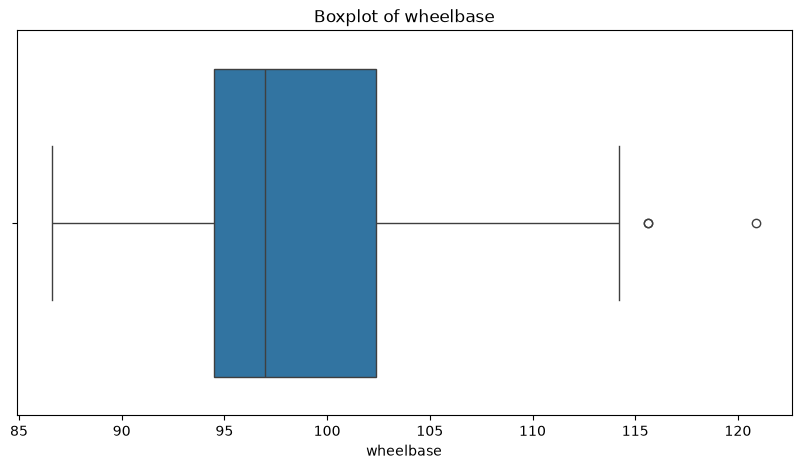

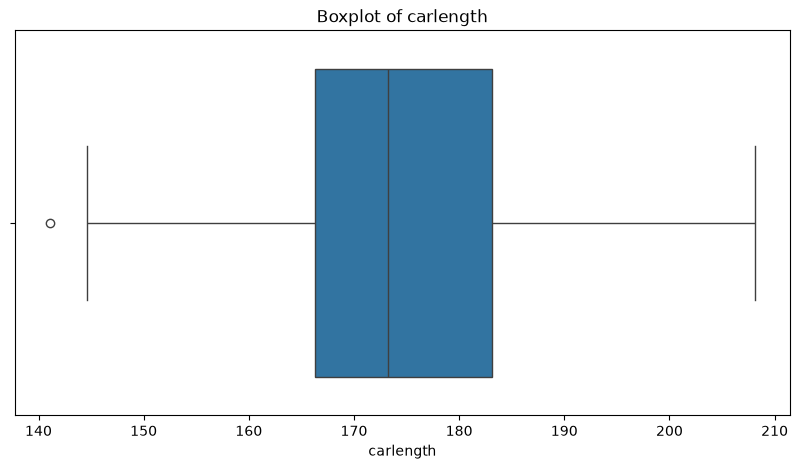

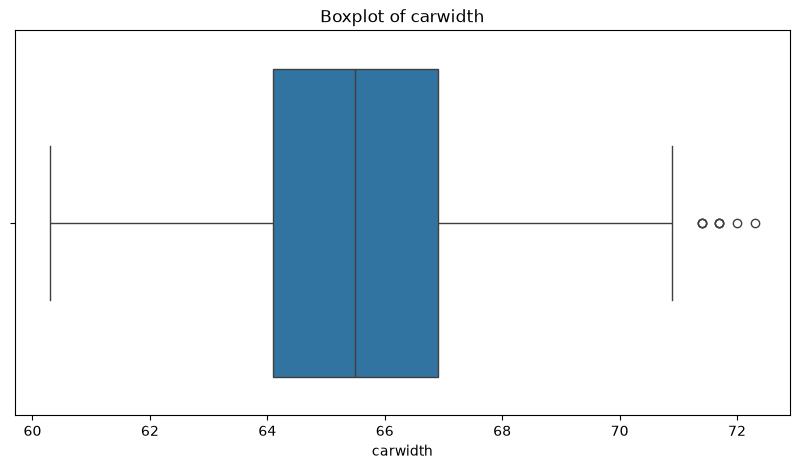

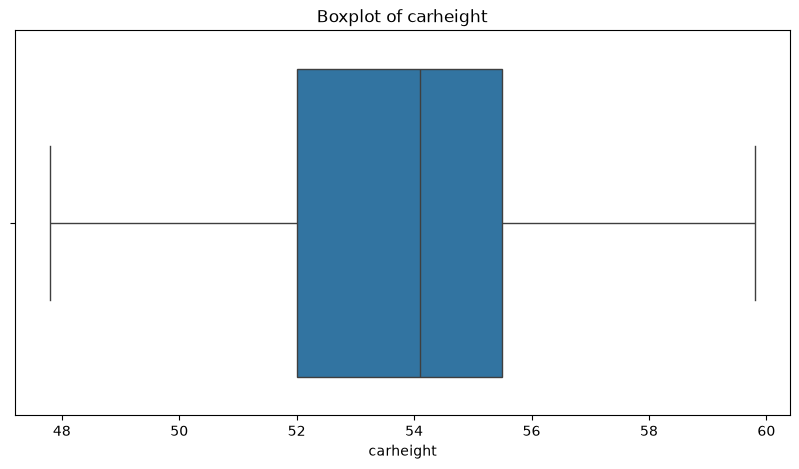

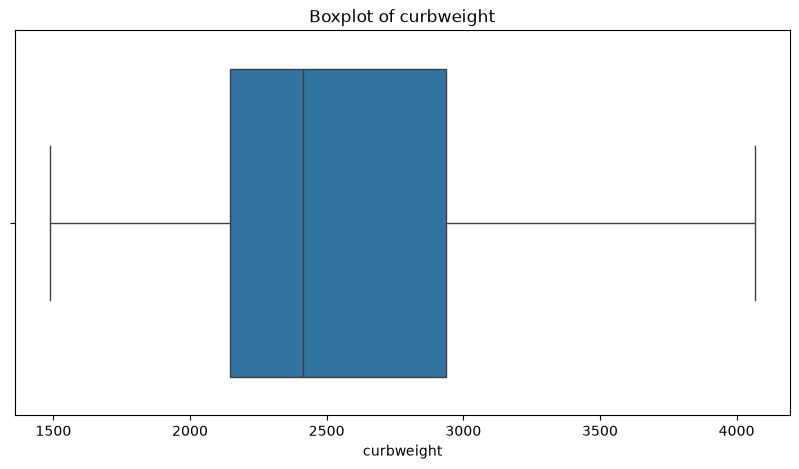

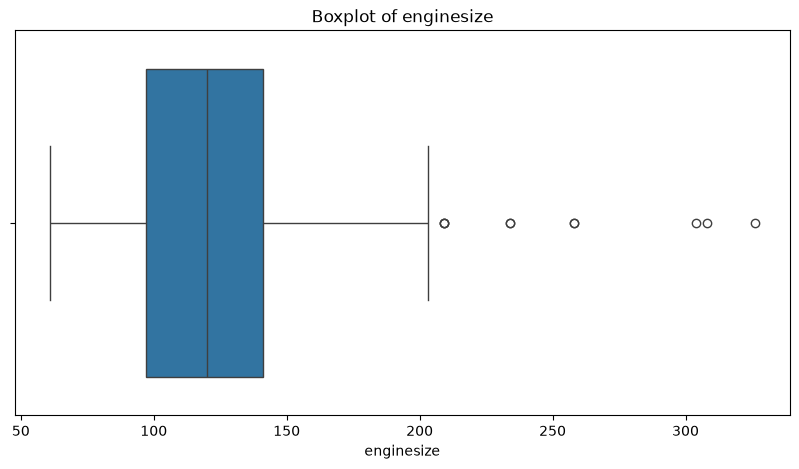

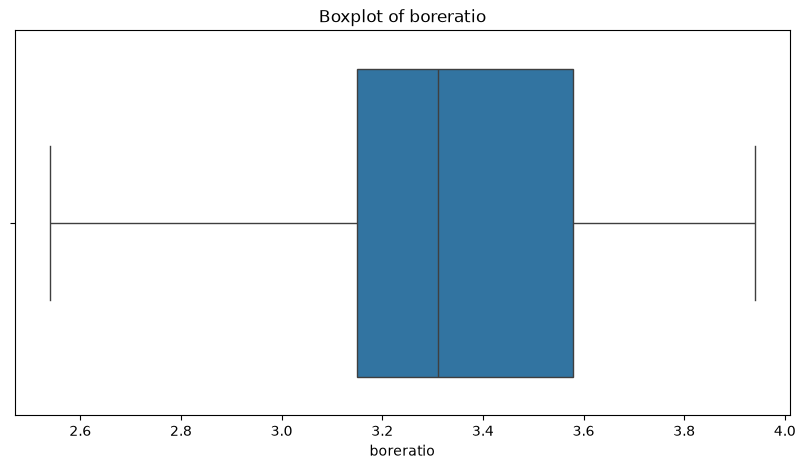

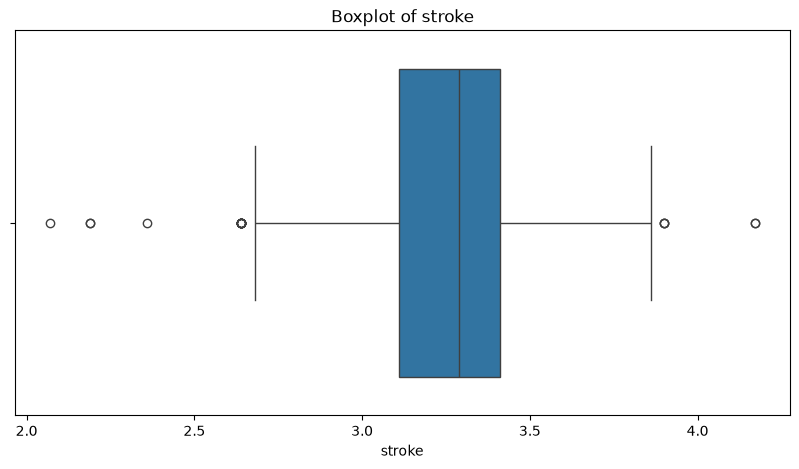

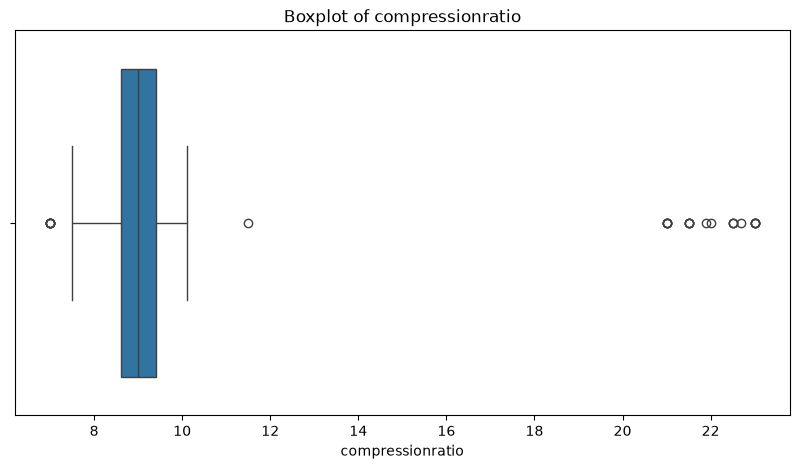

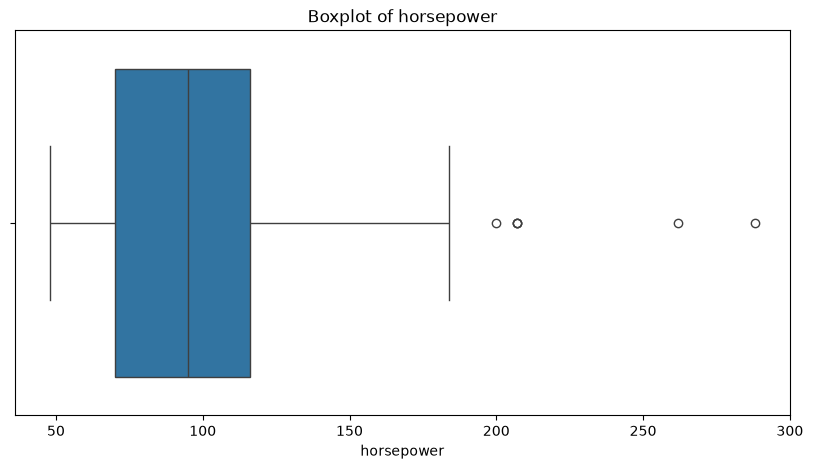

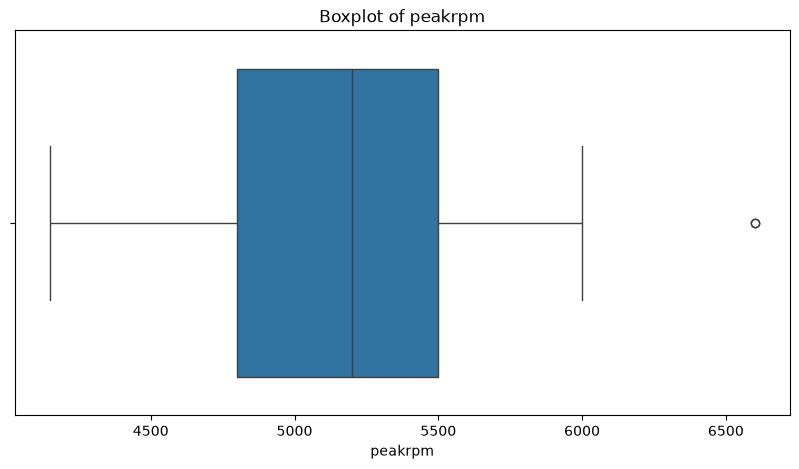

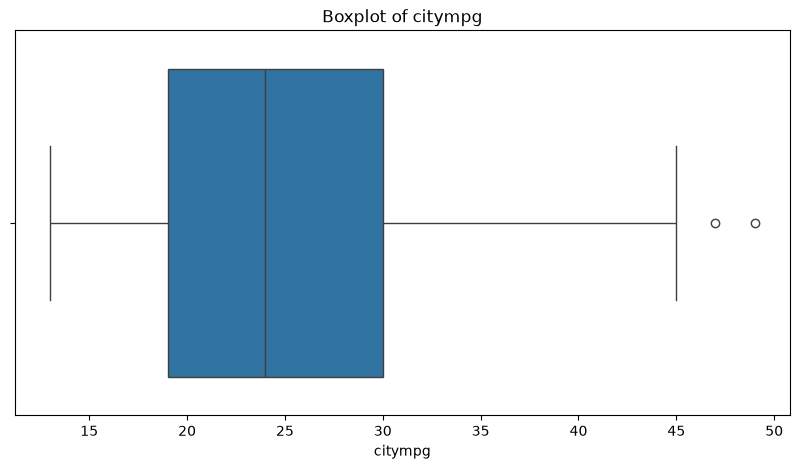

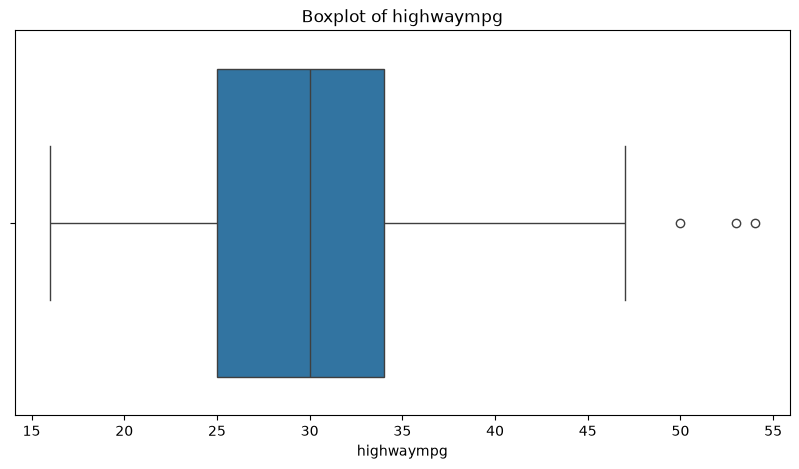

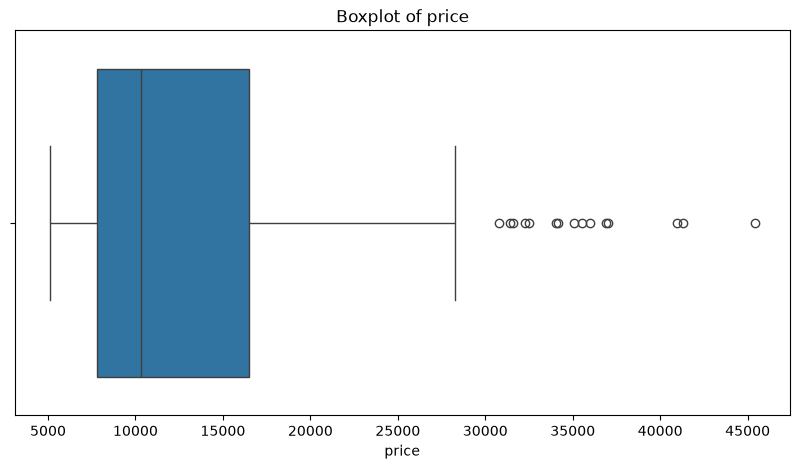

In [15]:
for col in num_cols:
    plt.figure(figsize=(10,5))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

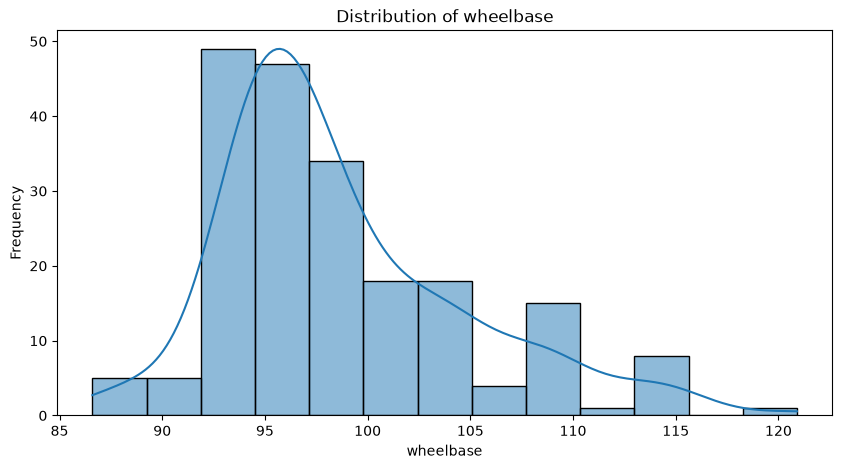

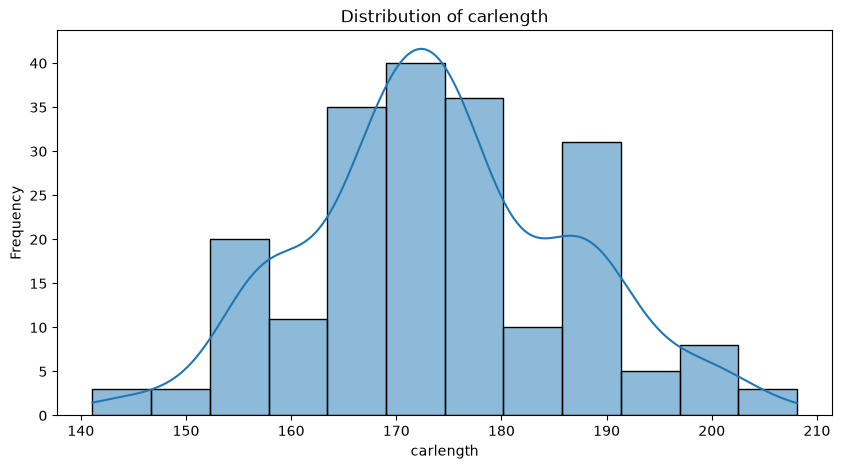

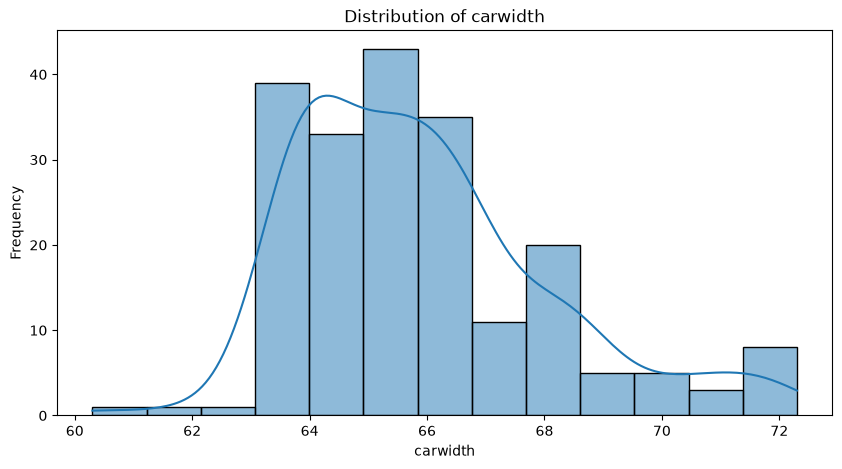

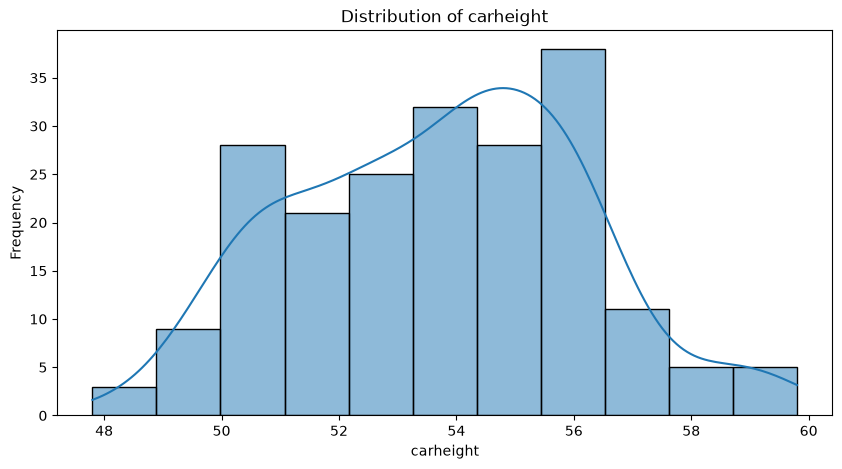

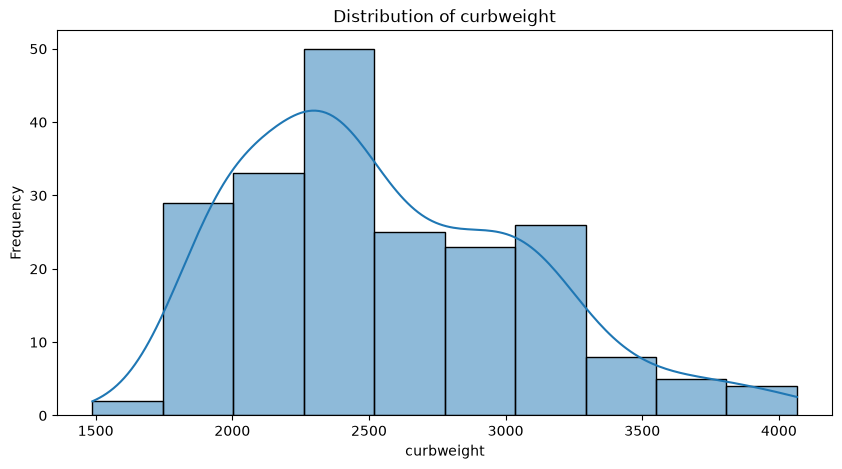

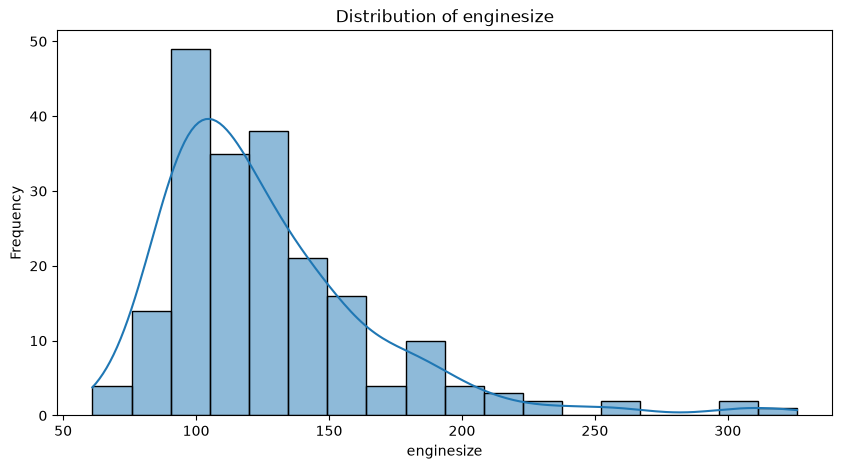

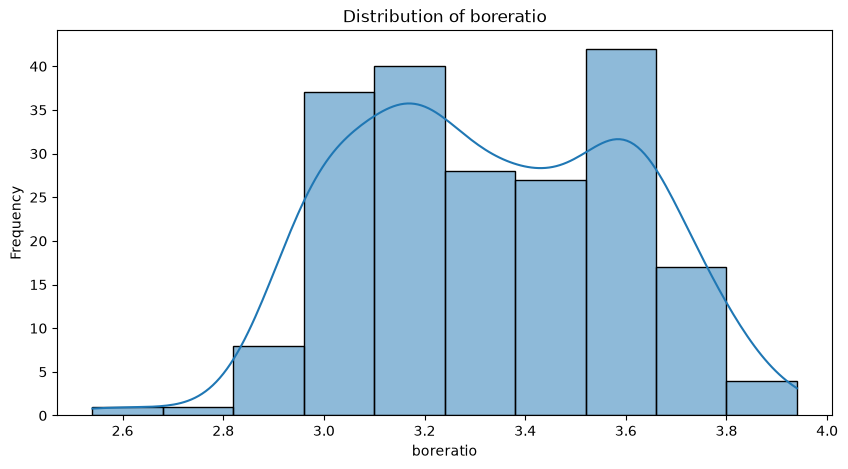

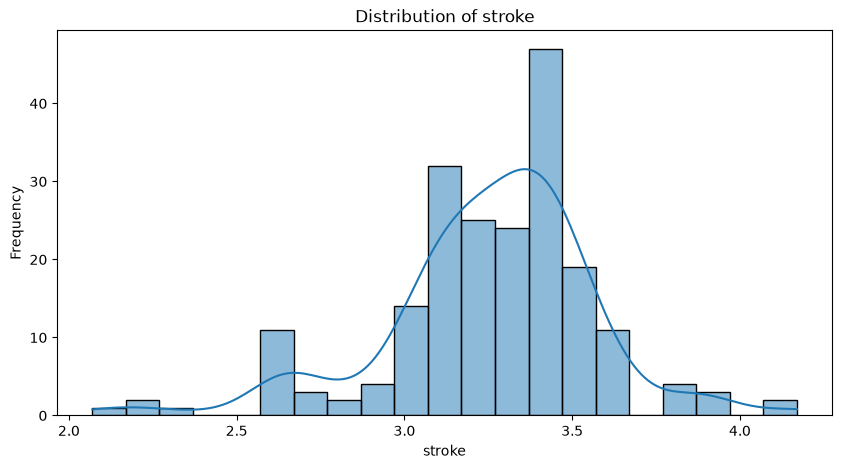

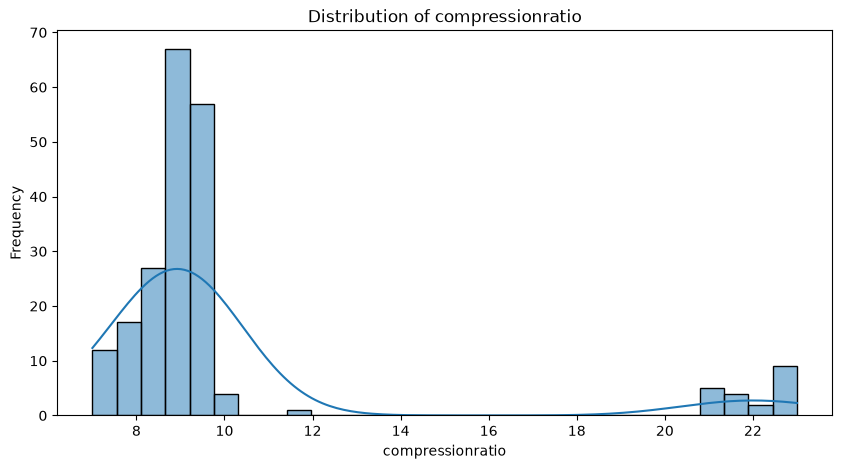

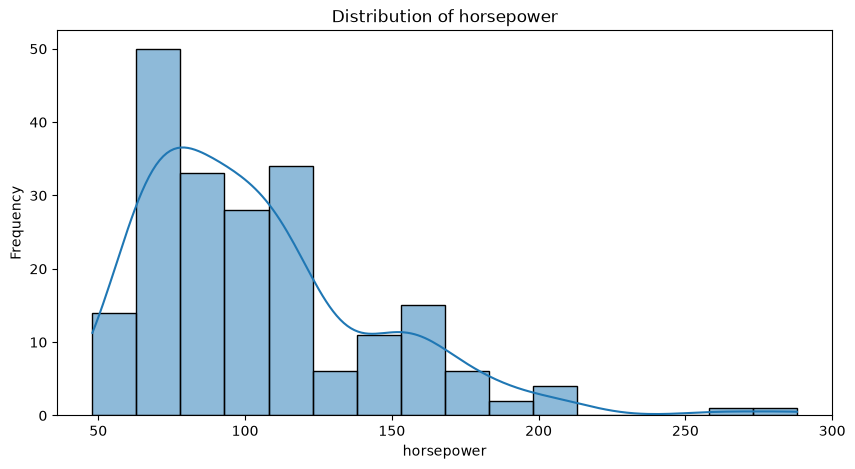

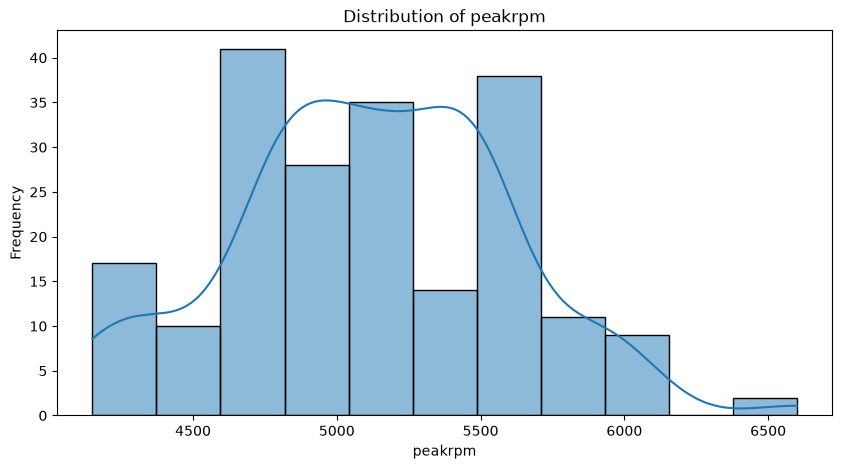

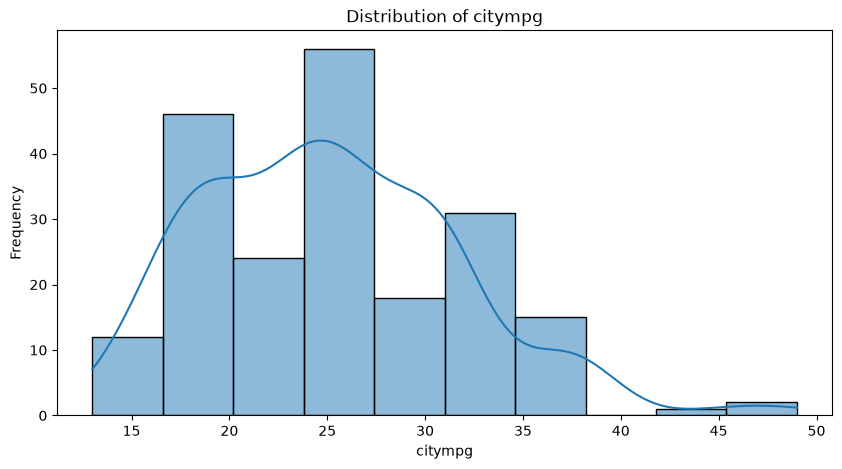

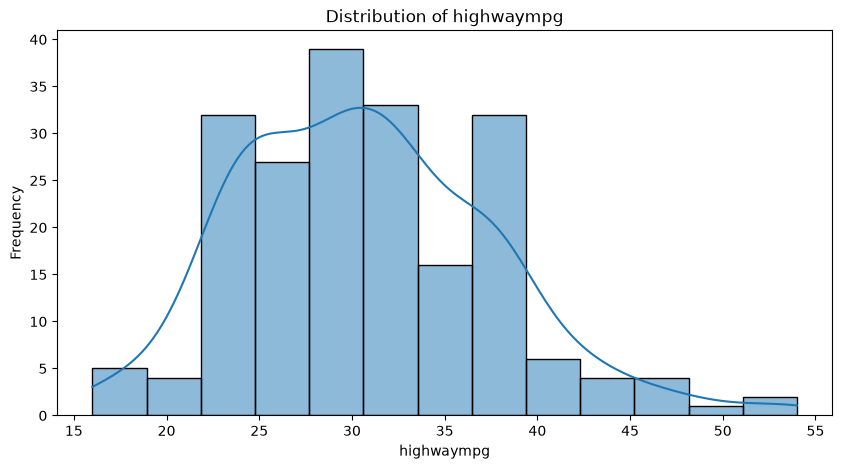

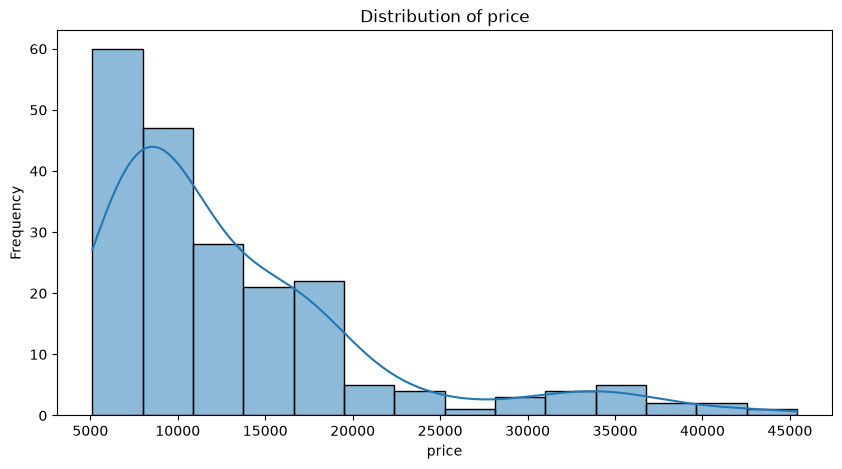

In [16]:
for col in num_cols:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [17]:
skewness = df[num_cols].skew().sort_values(ascending=False)
skewness

compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

- 'price', 'enginesize', 'horsepower', and 'compressionratio' are highly right-skewed.
- Most other numerical variables show mild to moderate skewness.
- 'price' is strongly right-skewed, so a log transformation can be explored during modeling.

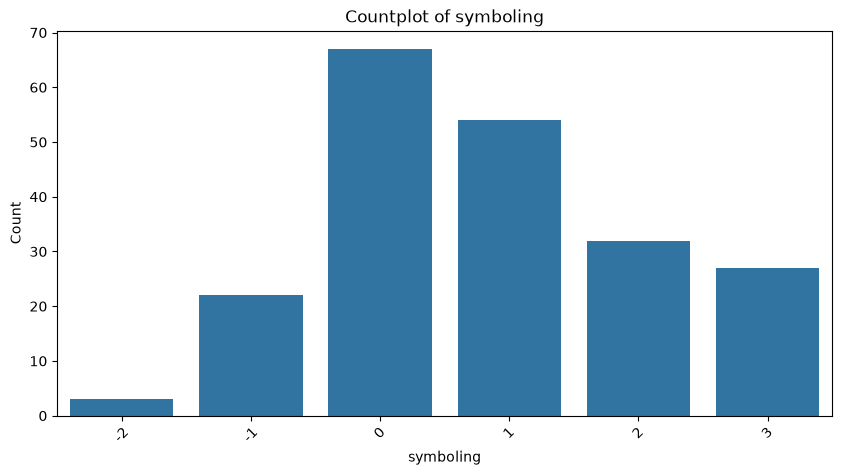

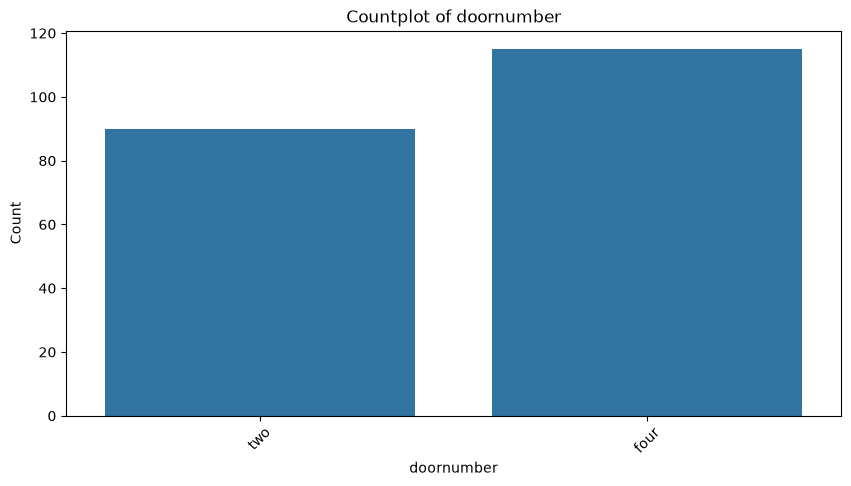

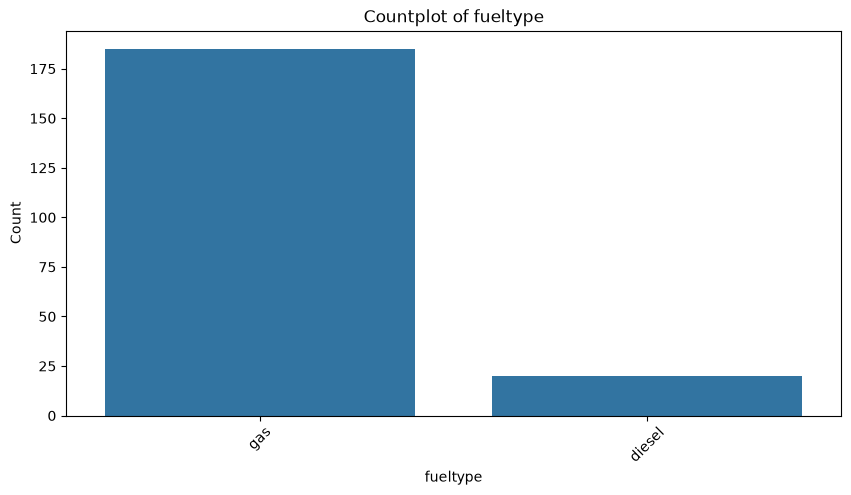

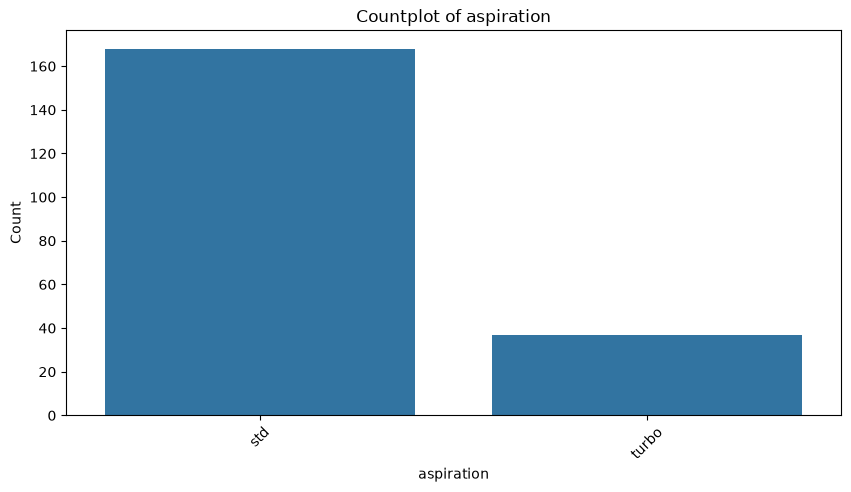

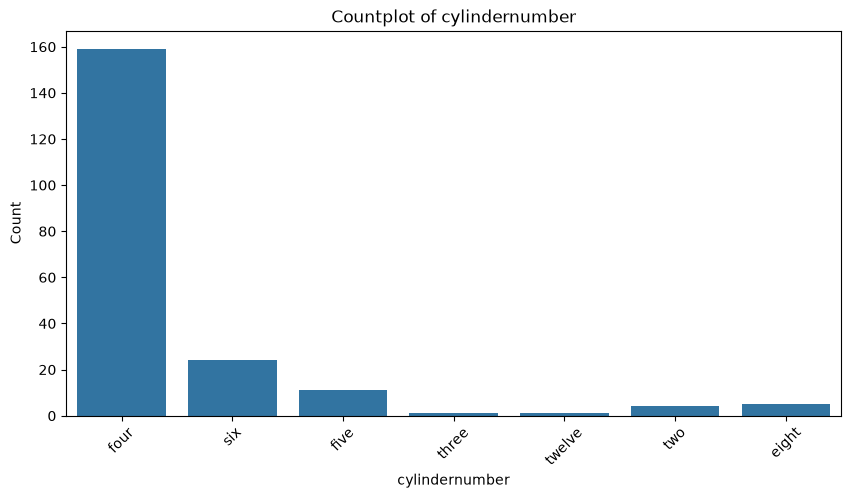

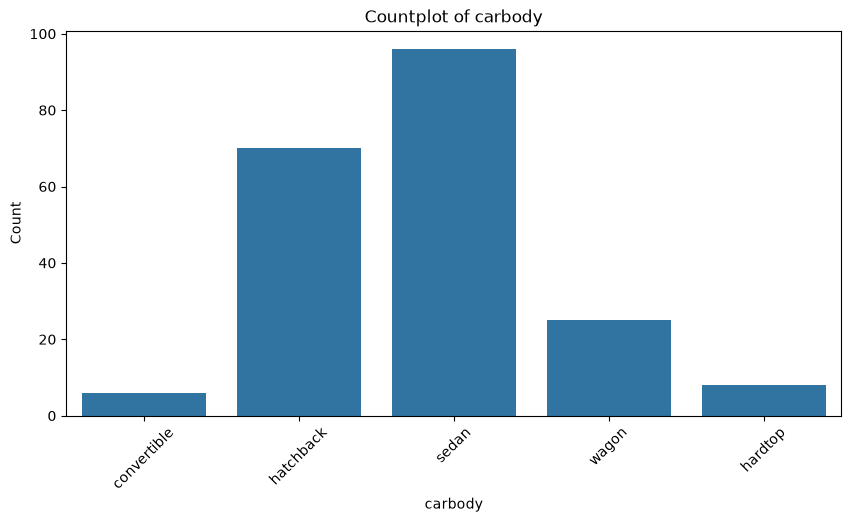

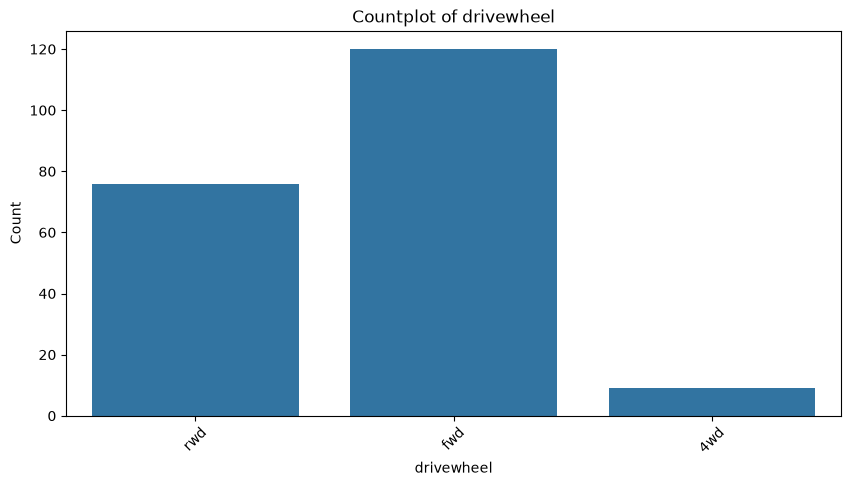

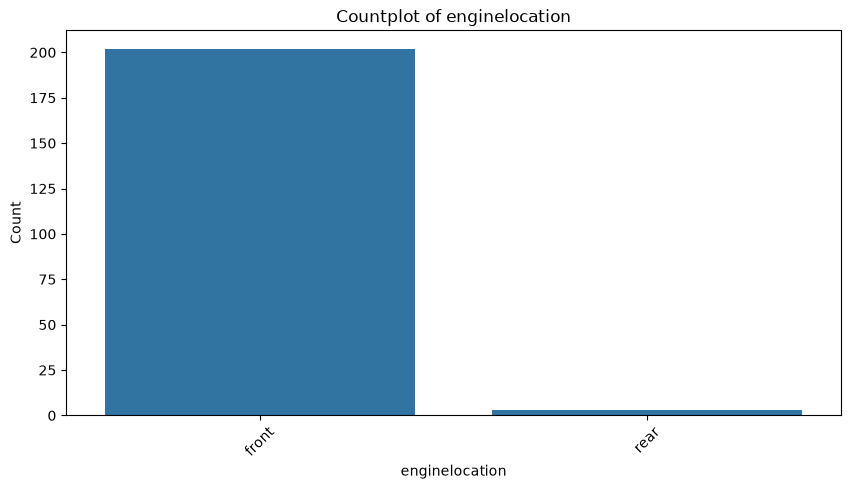

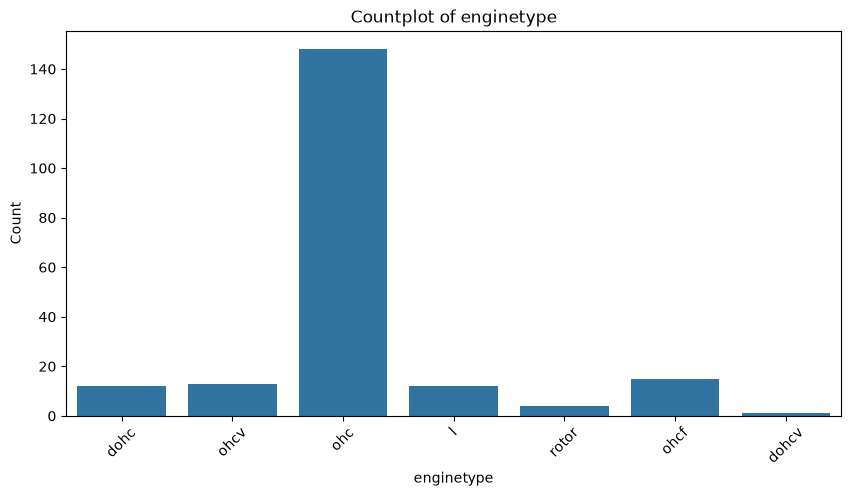

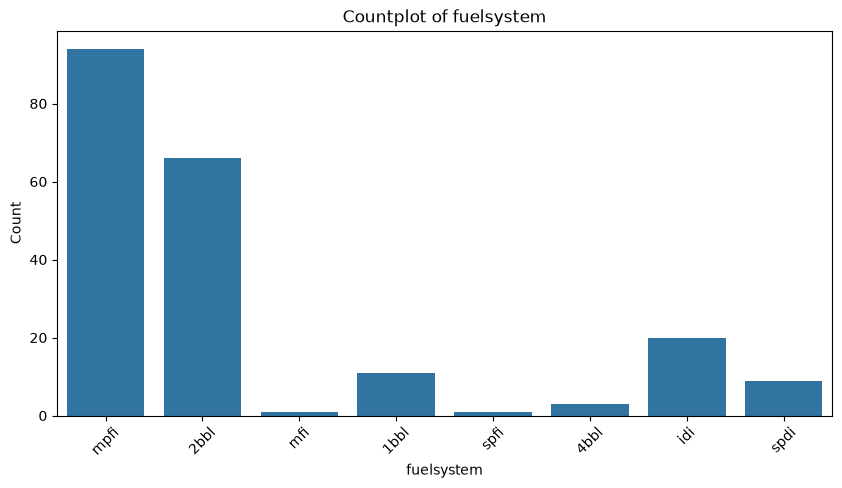

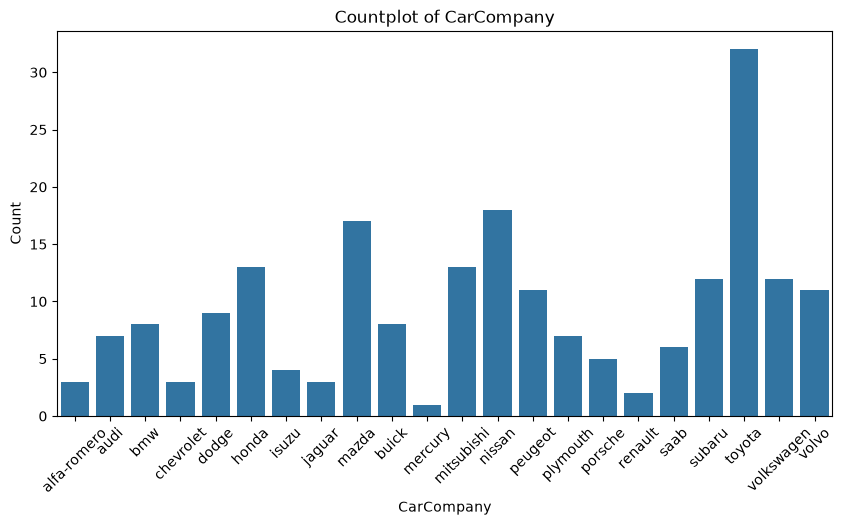

In [18]:
for col in cat_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(x=df[col])
    plt.title(f'Countplot of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()

#### Bivariate Analysis

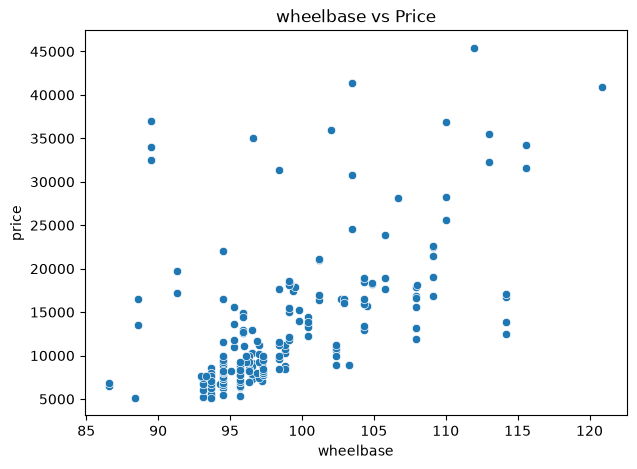

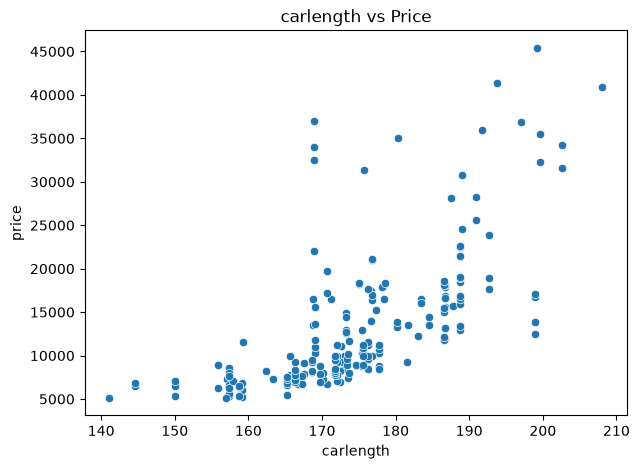

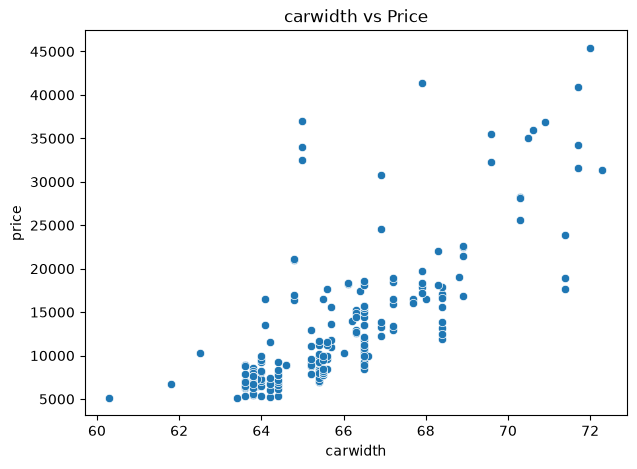

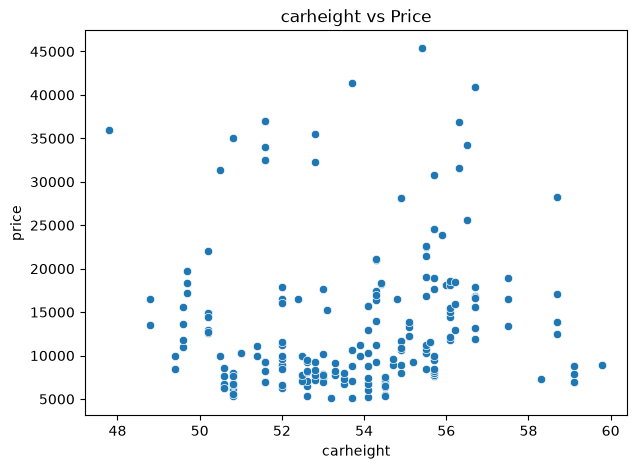

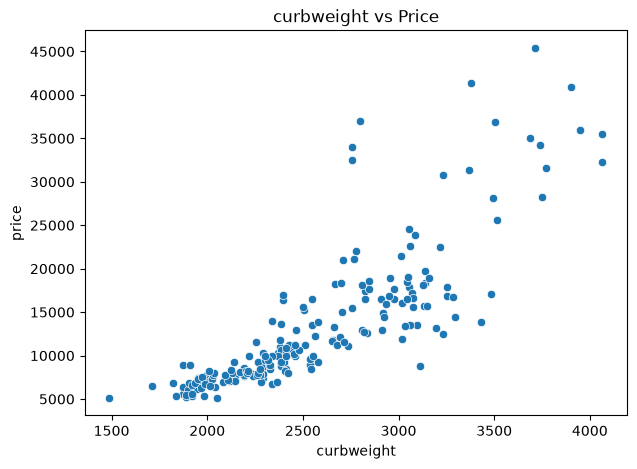

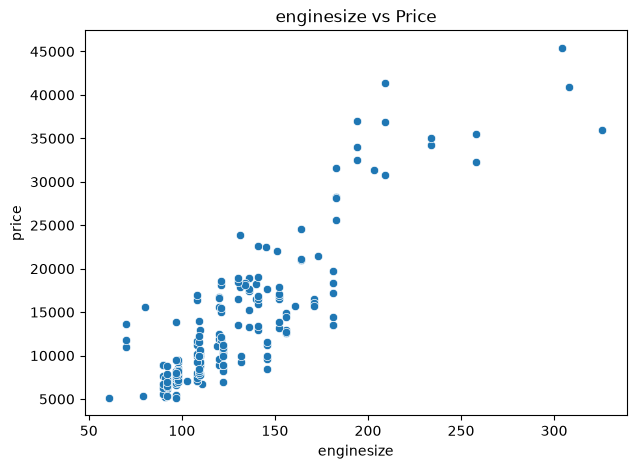

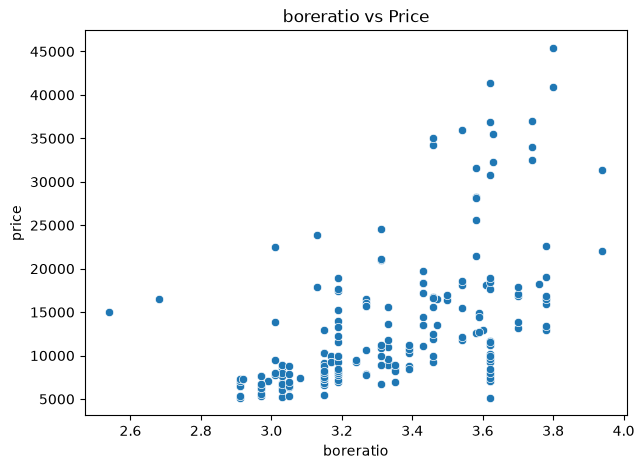

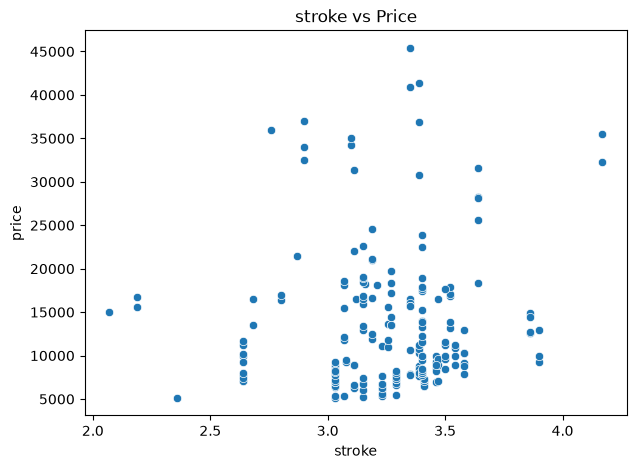

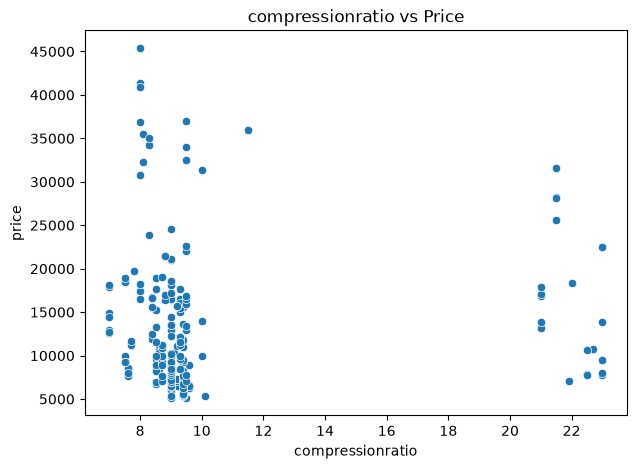

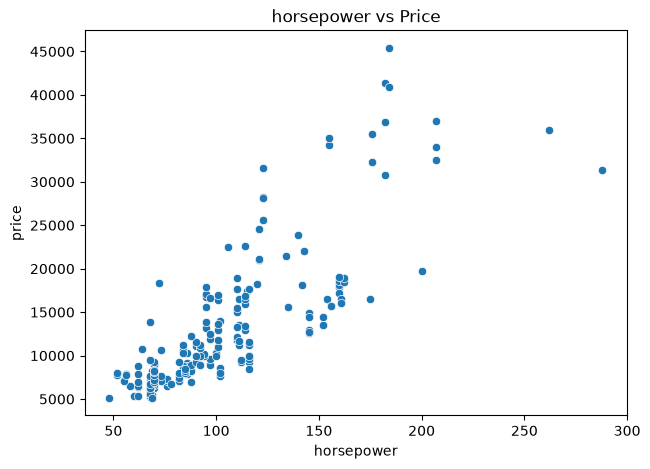

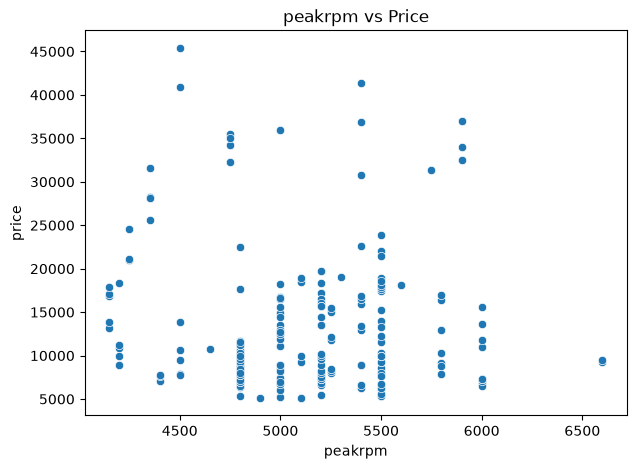

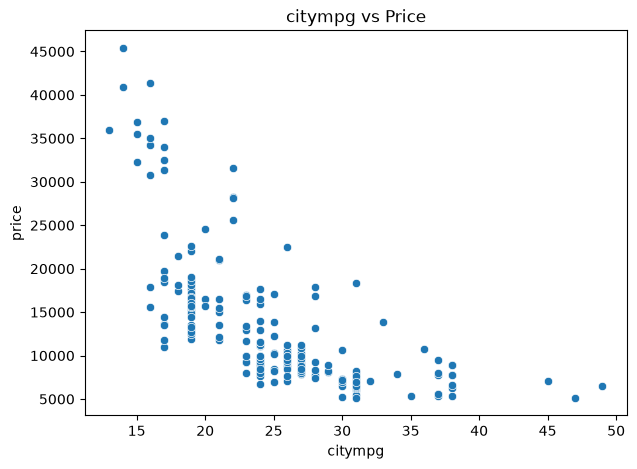

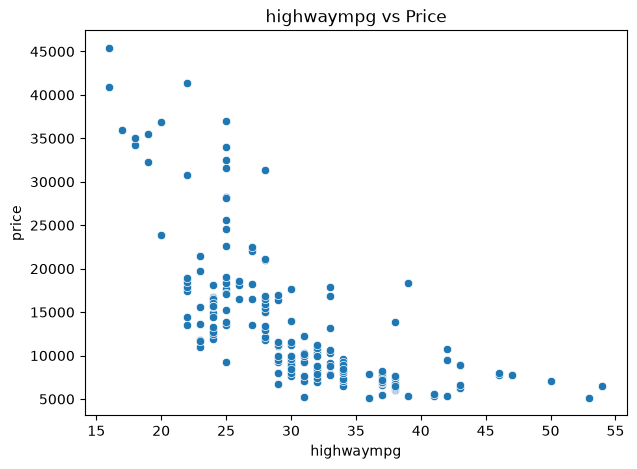

In [19]:
for col in num_cols:
    if col != 'price':
        plt.figure(figsize=(7,5))
        sns.scatterplot(x=df[col], y=df['price'])
        plt.title(f'{col} vs Price')
        plt.show()

##### Key Findings
- Some features show a positive linear relationship with price although there is considerable variation.
- Some features show a negative linear relationship with price although the relationship is relatively scattered.
- Some features have a weak or non-linear relationship with price.

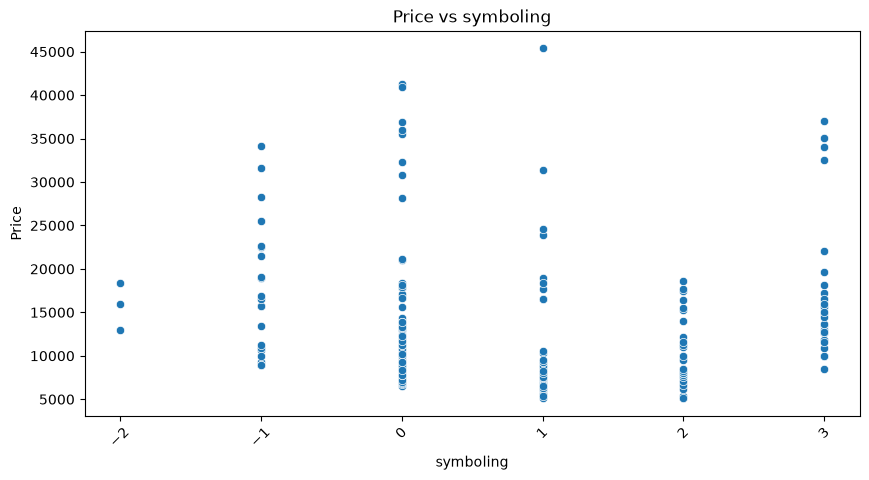

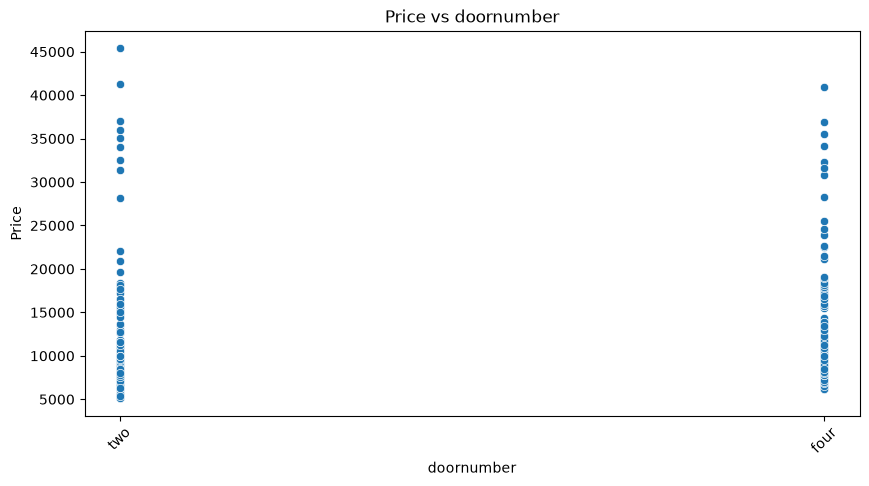

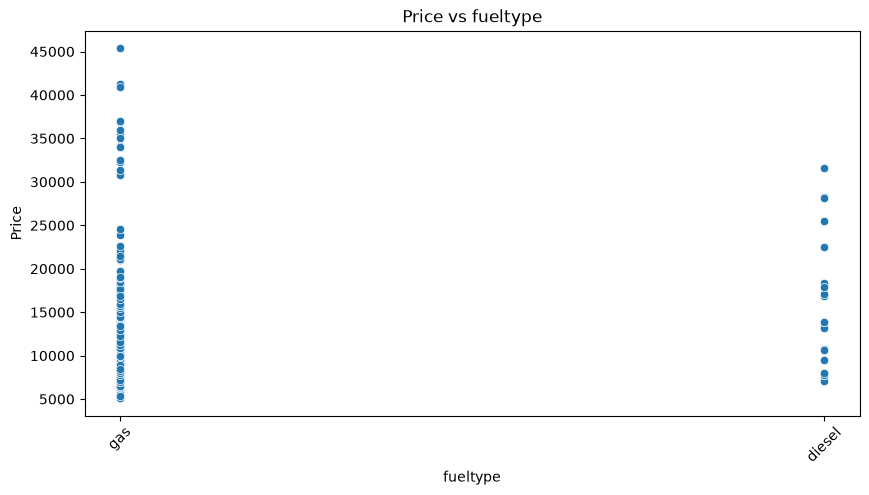

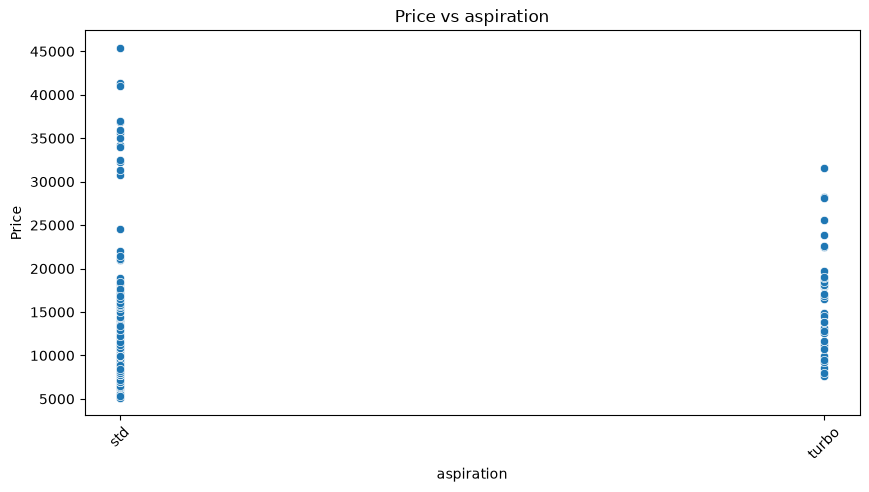

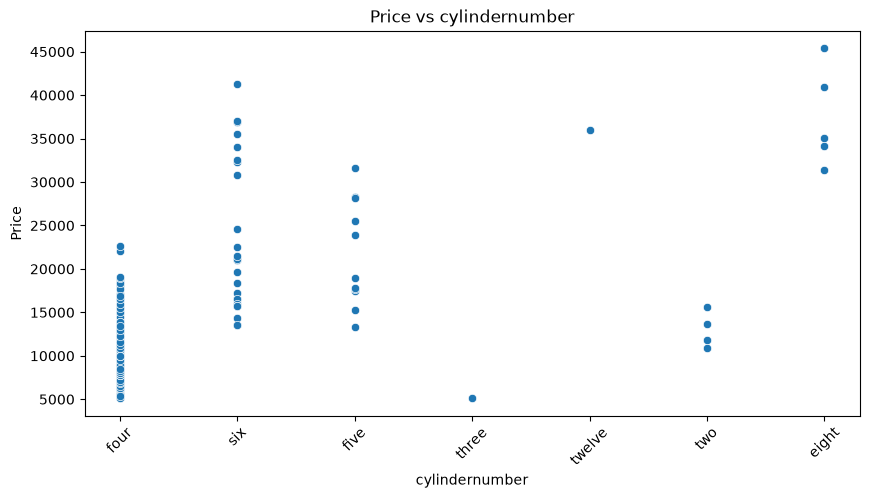

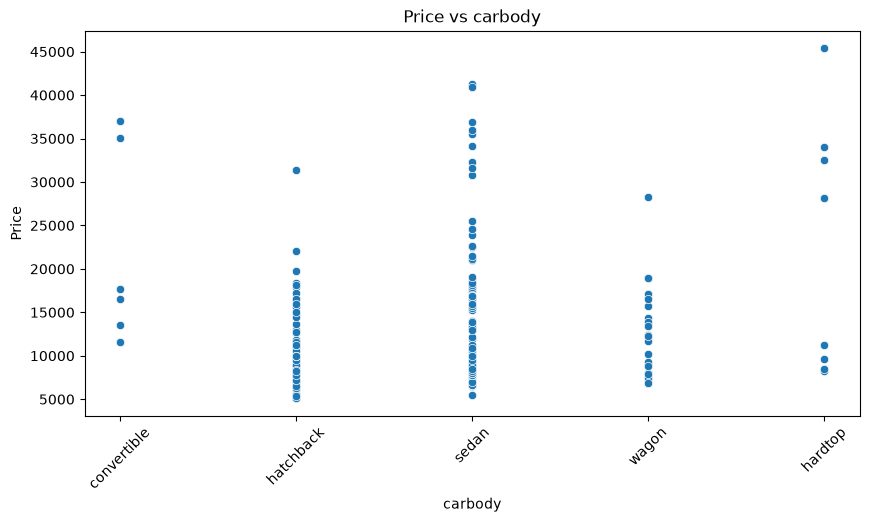

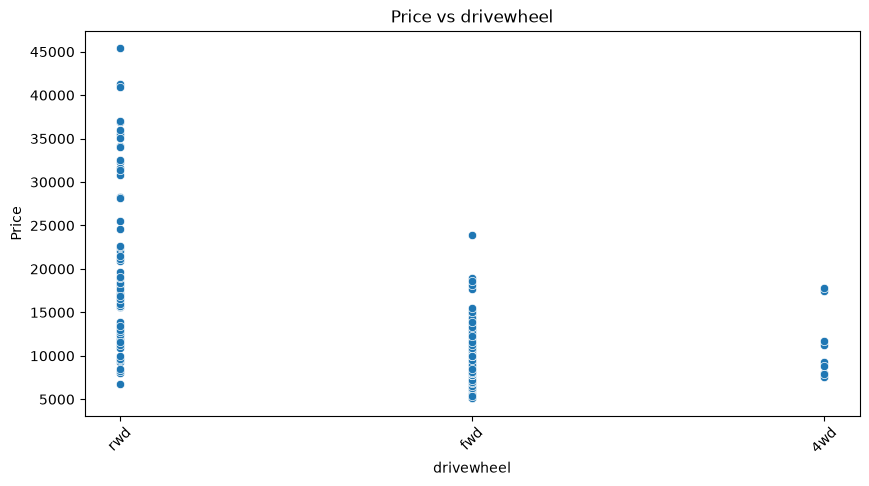

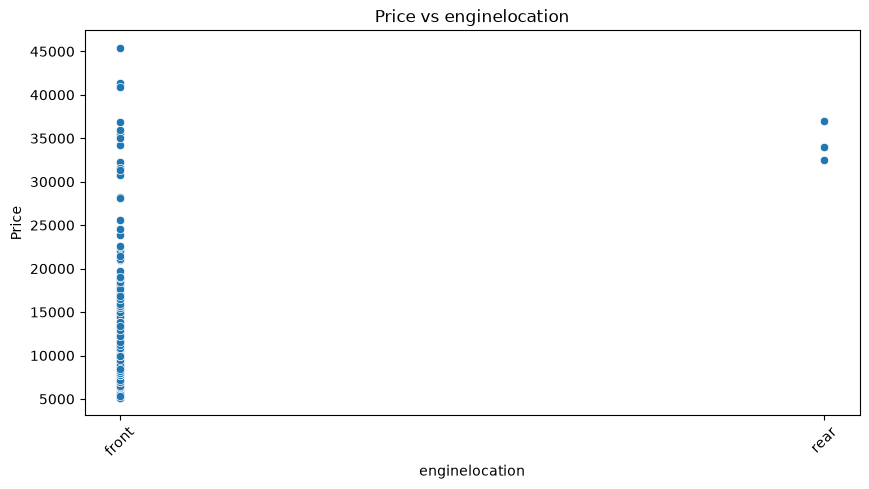

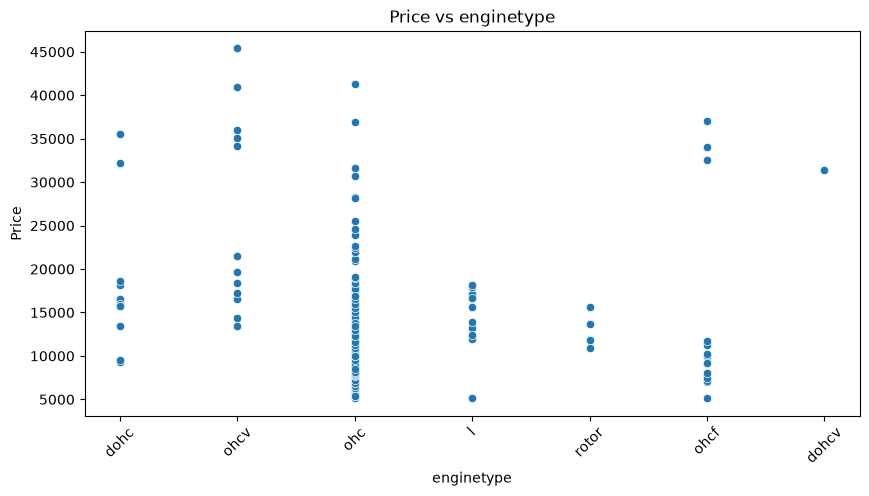

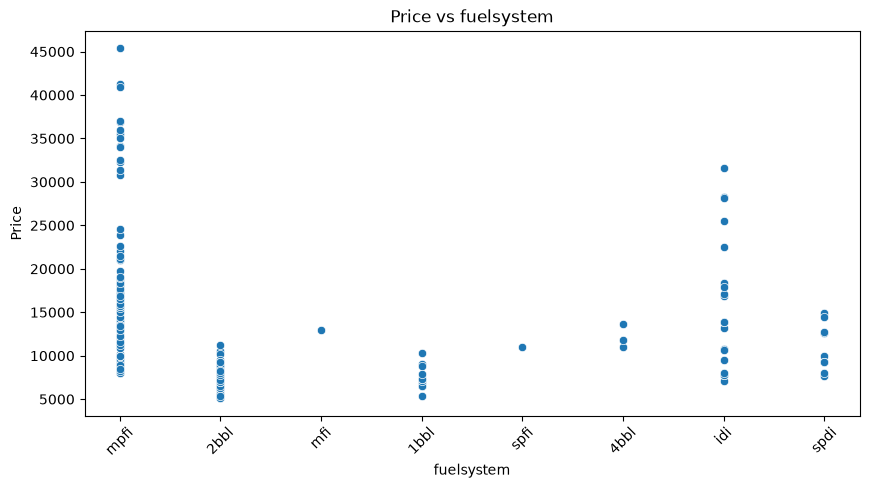

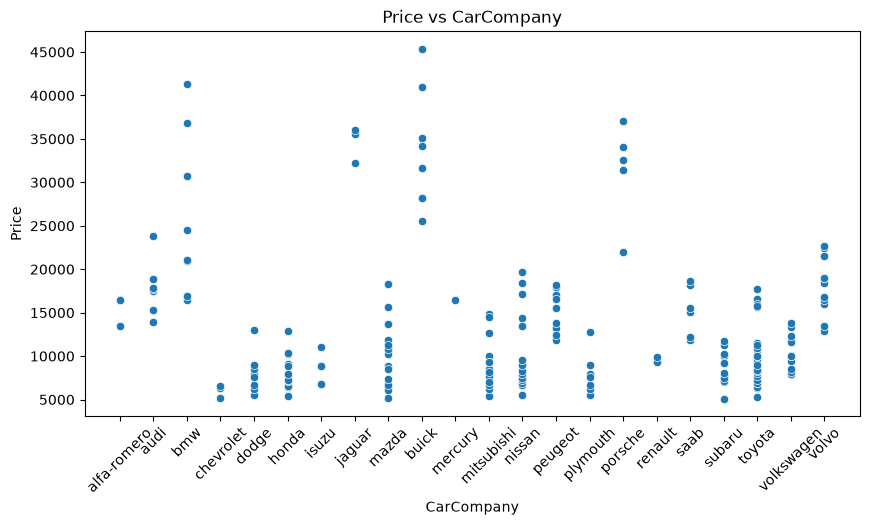

In [20]:
for col in cat_cols:
    plt.figure(figsize=(10, 5))
    sns.scatterplot(x=df[col], y=df['price'])
    plt.title(f'Price vs {col}')
    plt.xlabel(col)
    plt.ylabel('Price')
    plt.xticks(rotation=45)
    plt.show()

#### Multivariate Analysis

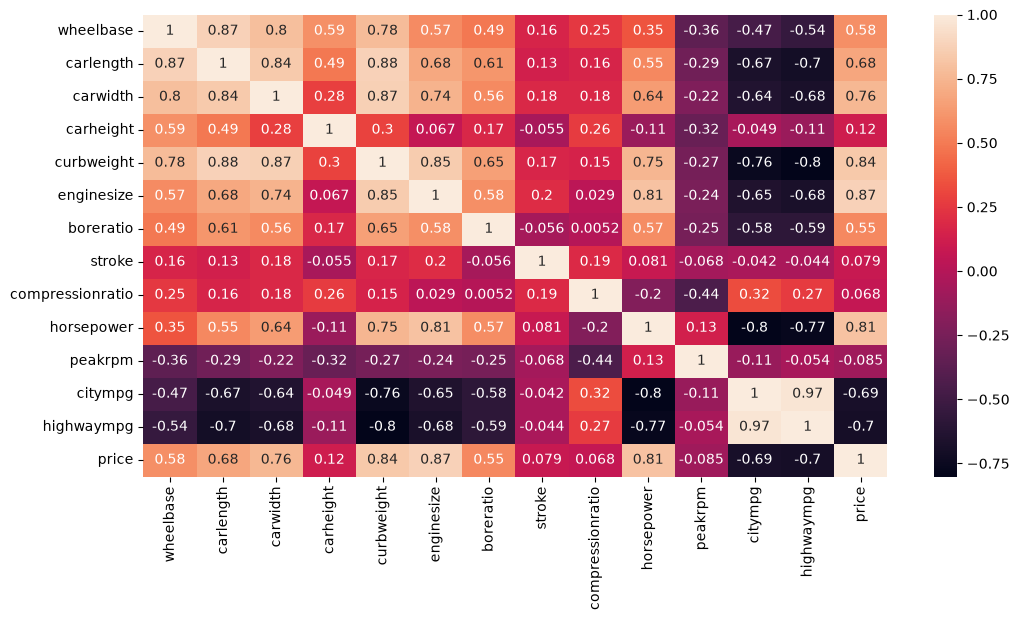

In [21]:
plt.figure(figsize=(12,6))
sns.heatmap(df[num_cols].corr(),annot=True)
plt.show()

- 'Price' column has a strong positive correlation with 'horsepower','enginesize', 'curbweight', and 'carwidth'.
- 'Price' column has a moderately strong correlation with 'boreratio', 'carlength' and wheelbase.
- 'Price' column has a moderately strong negative correlation with 'highwaympg' and 'citympg'.

#### **Train-Test Split**

In [22]:
X = df.drop(['price', 'car_ID','CarName'], axis=1)
y = df['price']#target

In [23]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [24]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((164, 24), (41, 24), (164,), (41,))

In [25]:
# print(X_train.columns)
# print(X_test.columns)

In [26]:
df[num_cols].head(2)

,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,13495.0
1,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,16500.0


In [27]:
num_cols.remove('price')

In [28]:
df[cat_cols].head(2)

,symboling,doornumber,fueltype,aspiration,cylindernumber,carbody,drivewheel,enginelocation,enginetype,fuelsystem,CarCompany
0,3,two,gas,std,four,convertible,rwd,front,dohc,mpfi,alfa-romero
1,3,two,gas,std,four,convertible,rwd,front,dohc,mpfi,alfa-romero


### **Scaling and One-Hot Encoding**

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [30]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
])

In [31]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

In [32]:
feature_names = preprocessor.get_feature_names_out()
# print(feature_names)

In [33]:
X_train_encoded

array([[ 1.03708546,  0.07244984,  0.08381686, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.54123134,  1.04391556,  1.17026768, ...,  0.        ,
         0.        ,  0.        ],
       [-0.50896191, -0.36761583, -1.09710795, ...,  1.        ,
         0.        ,  0.        ],
       ...,
       [-0.71062026, -0.73295337, -1.00263396, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.70098821,  0.77821554,  0.83960873, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.28086664,  0.86954992,  0.27276483, ...,  0.        ,
         0.        ,  0.        ]], shape=(164, 67))

In [34]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)
print(len(feature_names))

(164, 67)
(41, 67)
67


In [35]:
X_train_df = pd.DataFrame(
    X_train_encoded,
    columns=feature_names
)

X_test_df = pd.DataFrame(
    X_test_encoded,
    columns=feature_names
)

### **Modeling**

#### Experimentation

In [36]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()

In [37]:
model1.fit(X_train_df, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](67,)","[ 1608.02,-2108.9 , 1086.9 ,...,-3722.02,-2188.87,-1704.73]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](67,)","['num__wheelbase','num__carlength','num__carwidth',..., 'cat__CarCompany_toyota','cat__CarCompany_volkswagen', 'cat__CarCompany_volvo']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.853e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,67
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(63)


In [38]:
y_pred = model1.predict(X_test_df)

In [39]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)

R2: 0.9019383871176648
MAE: 1911.29863422324
RMSE: 2782.333196235845


In [40]:
y_train_pred = model1.predict(X_train_df)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)

print("Train R2:", train_r2)
print("Test R2:", test_r2)

Train R2: 0.9755725047969872
Test R2: 0.9019383871176648


In [41]:
# print(model1.coef_)

In [42]:
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model1.coef_
})

coef_df = coef_df.sort_values(
    by='Coefficient',
    ascending=False
)

coef_df

,Feature,Coefficient
32,cat__enginelocation_rear,8083.900436
47,cat__CarCompany_bmw,4542.797729
48,cat__CarCompany_buick,3694.474236
5,num__enginesize,3499.064344
4,num__curbweight,3344.937323
...,...,...
63,cat__CarCompany_subaru,-5065.838146
55,cat__CarCompany_mercury,-5112.201207
50,cat__CarCompany_dodge,-5165.137736
33,cat__enginetype_dohcv,-6593.725888


In [43]:
# X_train_df.columns

In [44]:
# %pip install statsmodels

### VIF based feature selection

In [45]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data=pd.DataFrame()
vif_data["Feature"]=X_train_df.columns

vif_data["VIF"]=[variance_inflation_factor(X_train_df.values,i) for i in range(len(X_train_df.columns))]

vif_data = vif_data.sort_values("VIF", ascending=False)
pd.set_option('display.max_rows', None)
vif_data

,Feature,VIF
25,cat__cylindernumber_two,inf
32,cat__enginelocation_rear,inf
34,cat__enginetype_l,inf
58,cat__CarCompany_peugeot,inf
63,cat__CarCompany_subaru,inf
38,cat__enginetype_rotor,inf
36,cat__enginetype_ohcf,inf
19,cat__fueltype_gas,1457.306925
41,cat__fuelsystem_idi,324.004978
8,num__compressionratio,292.868543


In [46]:
num_features = X_train_df.filter(like='num__')

vif_num = pd.DataFrame()

vif_num["Feature"] = num_features.columns

vif_num["VIF"] = [
    variance_inflation_factor(num_features.values, i)
    for i in range(num_features.shape[1])
]

vif_num = vif_num.sort_values("VIF", ascending=False)

vif_num

,Feature,VIF
11,num__citympg,24.772594
12,num__highwaympg,20.059902
4,num__curbweight,15.463227
1,num__carlength,8.790403
9,num__horsepower,7.686462
0,num__wheelbase,7.326036
5,num__enginesize,6.691813
2,num__carwidth,4.915274
8,num__compressionratio,2.202373
3,num__carheight,2.159525


In [47]:
X_train_df = X_train_df.drop(columns=['num__highwaympg'])
X_test_df = X_test_df.drop(columns=['num__highwaympg'])

In [48]:
num_features = X_train_df.filter(like='num__')

vif_num = pd.DataFrame()

vif_num["Feature"] = num_features.columns

vif_num["VIF"] = [
    variance_inflation_factor(num_features.values, i)
    for i in range(num_features.shape[1])
]

vif_num = vif_num.sort_values("VIF", ascending=False)

vif_num

,Feature,VIF
4,num__curbweight,14.795974
1,num__carlength,8.433320
9,num__horsepower,7.320076
0,num__wheelbase,6.957045
11,num__citympg,6.657561
5,num__enginesize,6.594236
2,num__carwidth,4.887575
8,num__compressionratio,2.195643
3,num__carheight,2.159309
10,num__peakrpm,2.084778


In [49]:
X_train_df = X_train_df.drop(columns=['num__curbweight'])
X_test_df = X_test_df.drop(columns=['num__curbweight'])

In [50]:
num_features = X_train_df.filter(like='num__')

vif_num = pd.DataFrame()

vif_num["Feature"] = num_features.columns

vif_num["VIF"] = [
    variance_inflation_factor(num_features.values, i)
    for i in range(num_features.shape[1])
]

vif_num = vif_num.sort_values("VIF", ascending=False)

vif_num

,Feature,VIF
1,num__carlength,8.013311
8,num__horsepower,7.127829
0,num__wheelbase,6.384730
4,num__enginesize,5.325354
10,num__citympg,5.225418
2,num__carwidth,4.848765
3,num__carheight,2.154947
9,num__peakrpm,2.054027
5,num__boreratio,1.965055
7,num__compressionratio,1.850608


In [51]:
X_train_df = X_train_df.drop(columns=['num__carlength'])
X_test_df = X_test_df.drop(columns=['num__carlength'])

In [52]:
num_features = X_train_df.filter(like='num__')

vif_num = pd.DataFrame()

vif_num["Feature"] = num_features.columns

vif_num["VIF"] = [
    variance_inflation_factor(num_features.values, i)
    for i in range(num_features.shape[1])
]

vif_num = vif_num.sort_values("VIF", ascending=False)

vif_num

,Feature,VIF
7,num__horsepower,7.119347
3,num__enginesize,5.265924
0,num__wheelbase,4.769932
1,num__carwidth,4.623957
9,num__citympg,4.349208
8,num__peakrpm,2.045379
2,num__carheight,2.029966
4,num__boreratio,1.956487
6,num__compressionratio,1.782692
5,num__stroke,1.156642


In [53]:
model2 = LinearRegression()
model2.fit(X_train_df, y_train)

y_train_pred = model2.predict(X_train_df)
y_pred = model2.predict(X_test_df)

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_pred))

Train R2: 0.9710890841803881
Test R2: 0.9028035391818848


- Some features were removed sequentially and the model was retrained using the remaining features. The model performance decreased significantly, so this model was not used for further experimentation.

In [54]:
cat_features = X_train_df.filter(like='cat__')

vif_cat = pd.DataFrame()

vif_cat["Feature"] = cat_features.columns

vif_cat["VIF"] = [
    variance_inflation_factor(cat_features.values, i)
    for i in range(cat_features.shape[1])
]

vif_cat = vif_cat.sort_values("VIF", ascending=False)

vif_cat

,Feature,VIF
21,cat__enginetype_l,inf
12,cat__cylindernumber_two,inf
19,cat__enginelocation_rear,inf
50,cat__CarCompany_subaru,inf
25,cat__enginetype_rotor,inf
23,cat__enginetype_ohcf,inf
45,cat__CarCompany_peugeot,inf
6,cat__fueltype_gas,860.103405
9,cat__cylindernumber_four,96.157711
28,cat__fuelsystem_idi,82.447808


In [55]:
pd.crosstab(df['fueltype'], df['fuelsystem'])

fuelsystem,1bbl,2bbl,4bbl,idi,mfi,mpfi,spdi,spfi
fueltype,,,,,,,,
diesel,0,0,0,20,0,0,0,0
gas,11,66,3,0,1,94,9,1


In [56]:
pd.crosstab(df['enginetype'], df['enginelocation'])

enginelocation,front,rear
enginetype,,
dohc,12,0
dohcv,1,0
l,12,0
ohc,148,0
ohcf,12,3
ohcv,13,0
rotor,4,0


In [57]:
pd.crosstab(df['enginetype'], df['cylindernumber'])

cylindernumber,eight,five,four,six,three,twelve,two
enginetype,,,,,,,
dohc,0,0,6,6,0,0,0
dohcv,1,0,0,0,0,0,0
l,0,0,11,0,1,0,0
ohc,0,11,130,7,0,0,0
ohcf,0,0,12,3,0,0,0
ohcv,4,0,0,8,0,1,0
rotor,0,0,0,0,0,0,4


In [58]:
# df['CarCompany'].value_counts().sort_values()

In [59]:
df = df.drop(columns=['fuelsystem'])

In [60]:
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price', 'CarCompany'],
      dtype='str')

In [61]:
X = df.drop(['price', 'car_ID','CarName'], axis=1)
y = df['price']

In [62]:
# X.columns

In [63]:
X['symboling'] = X['symboling'].astype('object')

In [64]:
# print(X['symboling'].dtype)

In [65]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [66]:
# X_train.shape, X_test.shape, y_train.shape, y_test.shape

In [67]:
new_num_cols = X.select_dtypes(include='number').columns.tolist()
new_cat_cols = X.select_dtypes(include='object').columns.tolist()

In [68]:
# print("Numerical columns:", new_num_cols)
# print("Categorical columns:", new_cat_cols)

In [69]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), new_num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), new_cat_cols)
])

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

In [70]:
feature_names = preprocessor.get_feature_names_out()


In [71]:
X_train_df = pd.DataFrame(
    X_train_encoded.toarray() if hasattr(X_train_encoded, 'toarray') else X_train_encoded,
    columns=feature_names,
    index=X_train.index
)

X_test_df = pd.DataFrame(
    X_test_encoded.toarray() if hasattr(X_test_encoded, 'toarray') else X_test_encoded,
    columns=feature_names,
    index=X_test.index
)

In [72]:
print(X_train_df.shape)
print(X_test_df.shape)

(164, 60)
(41, 60)


In [73]:
from sklearn.linear_model import LinearRegression

model3 = LinearRegression()

model3.fit(X_train_df, y_train)

y_train_pred = model3.predict(X_train_df)
y_test_pred = model3.predict(X_test_df)

In [74]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))

print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Train R2: 0.974246767486074
Test R2: 0.9019373831037952
Train MAE: 959.372354735384
Test MAE: 1938.0728248345683
Train RMSE: 1239.3010501203926
Test RMSE: 2782.347439801122


In [75]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Feature"] = X_train_df.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_train_df.values, i)
    for i in range(X_train_df.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)

vif_data

,Feature,VIF
27,cat__enginelocation_rear,inf
33,cat__enginetype_rotor,inf
31,cat__enginetype_ohcf,inf
29,cat__enginetype_l,inf
38,cat__cylindernumber_two,inf
56,cat__CarCompany_subaru,inf
51,cat__CarCompany_peugeot,inf
18,cat__fueltype_gas,1146.962464
35,cat__cylindernumber_four,768.006307
8,num__compressionratio,123.827748


In [76]:
X_train_cat = X_train.drop(columns=['enginelocation'])
X_test_cat = X_test.drop(columns=['enginelocation'])

In [77]:
new_num_cols = X_train_cat.select_dtypes(include='number').columns.tolist()
new_cat_cols = X_train_cat.select_dtypes(include='object').columns.tolist()

# print("Numerical:", new_num_cols)
# print("Categorical:", new_cat_cols)

In [78]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), new_num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), new_cat_cols)
])

In [79]:
X_train_encoded = preprocessor.fit_transform(X_train_cat)
X_test_encoded = preprocessor.transform(X_test_cat)

In [80]:
feature_names = preprocessor.get_feature_names_out()

In [81]:
X_train_df = pd.DataFrame(
    X_train_encoded.toarray() if hasattr(X_train_encoded, 'toarray') else X_train_encoded,
    columns=feature_names,
    index=X_train_cat.index
)

X_test_df = pd.DataFrame(
    X_test_encoded.toarray() if hasattr(X_test_encoded, 'toarray') else X_test_encoded,
    columns=feature_names,
    index=X_test_cat.index
)

In [82]:
print(X_train_df.shape)
print(X_test_df.shape)

(164, 59)
(41, 59)


In [83]:
model4 = LinearRegression()

model4.fit(X_train_df, y_train)

y_train_pred = model4.predict(X_train_df)
y_test_pred = model4.predict(X_test_df)

In [84]:
print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))
print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Train R2: 0.974246767486074
Test R2: 0.9019373831037953
Train MAE: 959.372354735384
Test MAE: 1938.072824834567
Train RMSE: 1239.3010501203928
Test RMSE: 2782.3474398011217


In [85]:
X_train_cat = X_train.drop(columns=['enginelocation', 'enginetype'])
X_test_cat = X_test.drop(columns=['enginelocation', 'enginetype'])

In [86]:
new_num_cols = X_train_cat.select_dtypes(include='number').columns.tolist()
new_cat_cols = X_train_cat.select_dtypes(include='object').columns.tolist()

In [87]:
# print("Numerical:", new_num_cols)
# print("Categorical:", new_cat_cols)

In [88]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), new_num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), new_cat_cols)
])

In [89]:
X_train_encoded = preprocessor.fit_transform(X_train_cat)
X_test_encoded = preprocessor.transform(X_test_cat)

In [90]:
feature_names = preprocessor.get_feature_names_out()

In [91]:
X_train_df = pd.DataFrame(
    X_train_encoded.toarray() if hasattr(X_train_encoded, 'toarray') else X_train_encoded,
    columns=feature_names,
    index=X_train_cat.index
)

X_test_df = pd.DataFrame(
    X_test_encoded.toarray() if hasattr(X_test_encoded, 'toarray') else X_test_encoded,
    columns=feature_names,
    index=X_test_cat.index
)

print(X_train_df.shape)
print(X_test_df.shape)

(164, 53)
(41, 53)


In [92]:
from sklearn.linear_model import LinearRegression

model5 = LinearRegression()

model5.fit(X_train_df, y_train)

y_train_pred = model5.predict(X_train_df)
y_test_pred = model5.predict(X_test_df)

In [93]:
print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))
print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Train R2: 0.9666568076995152
Test R2: 0.8739923347321416
Train MAE: 1048.5933144013334
Test MAE: 2107.0820743389804
Train RMSE: 1410.1474675886254
Test RMSE: 3153.9739627813565


In [94]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data["Feature"] = X_train_df.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_train_df.values, i)
    for i in range(X_train_df.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)

vif_data

,Feature,VIF
18,cat__fueltype_gas,566.622959
28,cat__cylindernumber_four,241.175703
5,num__enginesize,55.134300
8,num__compressionratio,51.811112
15,cat__symboling_1,49.821326
14,cat__symboling_0,49.651684
11,num__citympg,47.517567
4,num__curbweight,46.638516
25,cat__drivewheel_fwd,39.635192
26,cat__drivewheel_rwd,37.159631


In [95]:
X_train.groupby('cylindernumber')['enginesize'].agg(['mean', 'min', 'max'])

,mean,min,max
cylindernumber,,,
eight,243.750000,203,304
five,143.000000,131,183
four,112.907692,79,156
six,183.750000,145,258
twelve,326.000000,326,326
two,73.333333,70,80


In [96]:
X_train_cat = X_train.drop(
    columns=['enginelocation', 'enginetype', 'cylindernumber']
)

X_test_cat = X_test.drop(
    columns=['enginelocation', 'enginetype', 'cylindernumber']
)

In [97]:
new_num_cols = X_train_cat.select_dtypes(include='number').columns.tolist()
new_cat_cols = X_train_cat.select_dtypes(include='object').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), new_num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), new_cat_cols)
])

X_train_encoded = preprocessor.fit_transform(X_train_cat)
X_test_encoded = preprocessor.transform(X_test_cat)

feature_names = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train_encoded.toarray() if hasattr(X_train_encoded, 'toarray') else X_train_encoded,
    columns=feature_names,
    index=X_train_cat.index
)

X_test_df = pd.DataFrame(
    X_test_encoded.toarray() if hasattr(X_test_encoded, 'toarray') else X_test_encoded,
    columns=feature_names,
    index=X_test_cat.index
)

In [98]:
model6 = LinearRegression()

model6.fit(X_train_df, y_train)

y_train_pred = model6.predict(X_train_df)
y_test_pred = model6.predict(X_test_df)

In [99]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))

print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Train R2: 0.9613357986029349
Test R2: 0.8813861908610096
Train MAE: 1150.794303659574
Test MAE: 2016.1403216723972
Train RMSE: 1518.5023396682416
Test RMSE: 3060.0410169283996


In [100]:
vif_data = pd.DataFrame()

vif_data["Feature"] = X_train_df.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_train_df.values, i)
    for i in range(X_train_df.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)

vif_data

,Feature,VIF
18,cat__fueltype_gas,334.344462
14,cat__symboling_0,47.117770
15,cat__symboling_1,46.846100
11,num__citympg,44.992955
4,num__curbweight,37.000550
12,num__highwaympg,36.449101
25,cat__drivewheel_fwd,36.004593
23,cat__carbody_sedan,34.360769
26,cat__drivewheel_rwd,33.248003
8,num__compressionratio,31.515896


In [101]:
X_train_df = X_train_df.drop(columns=['cat__fueltype_gas'])
X_test_df = X_test_df.drop(columns=['cat__fueltype_gas'])

In [102]:
model7 = LinearRegression()

model7.fit(X_train_df, y_train)

y_train_pred = model7.predict(X_train_df)
y_test_pred = model7.predict(X_test_df)

In [103]:
print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))

print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Train R2: 0.9613310316453834
Test R2: 0.880880294873739
Train MAE: 1150.607090323968
Test MAE: 2019.0793181081876
Train RMSE: 1518.5959458056022
Test RMSE: 3066.5597154900174


In [104]:
pd.crosstab(X_train['symboling'], X_train['carbody'])

carbody,convertible,hardtop,hatchback,sedan,wagon
symboling,,,,,
-2,0,0,0,2,0
-1,0,0,1,11,5
0,0,0,6,31,12
1,0,1,22,21,2
2,1,2,11,13,0
3,5,2,16,0,0


In [105]:
pd.crosstab(X_train['symboling'], X_train['drivewheel'])

drivewheel,4wd,fwd,rwd
symboling,,,
-2,0,0,2
-1,0,7,10
0,4,25,20
1,0,37,9
2,2,18,7
3,0,8,15


In [106]:
symboling_cols = [
    col for col in X_train_df.columns
    if col.startswith("cat__symboling_")
]

symboling_cols

['cat__symboling_-1',
 'cat__symboling_0',
 'cat__symboling_1',
 'cat__symboling_2',
 'cat__symboling_3']

In [107]:
X_train_df = X_train_df.drop(columns=symboling_cols)
X_test_df = X_test_df.drop(columns=symboling_cols)

In [108]:
model8 = LinearRegression()

model8.fit(X_train_df, y_train)

y_train_pred = model8.predict(X_train_df)
y_test_pred = model8.predict(X_test_df)

In [109]:
print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))

print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Train R2: 0.9598657923394074
Test R2: 0.8820729423448851
Train MAE: 1157.9970860301332
Test MAE: 2002.2889518147113
Train RMSE: 1547.0996574489284
Test RMSE: 3051.1696284870804


In [110]:
vif_data = pd.DataFrame()

vif_data["Feature"] = X_train_df.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_train_df.values, i)
    for i in range(X_train_df.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)

vif_data

,Feature,VIF
11,num__citympg,42.346934
4,num__curbweight,33.897608
12,num__highwaympg,33.485293
17,cat__carbody_sedan,27.411194
5,num__enginesize,23.520185
19,cat__drivewheel_fwd,22.752367
9,num__horsepower,20.619503
1,num__carlength,19.359745
20,cat__drivewheel_rwd,18.440879
16,cat__carbody_hatchback,17.138396


#### Cross-Validation

Performing cross-validation to evaluate the model's performance and generalisation ability.

In [111]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
import numpy as np

# Create pipeline
model_final = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    model_final,
    X,
    y,
    cv=kf,
    scoring='r2'
)

print("CV R2 scores:", cv_scores)
print("Mean CV R2:", cv_scores.mean())
print("Std CV R2:", cv_scores.std())

CV R2 scores: [0.88138619 0.85859033 0.81451704 0.89821664 0.87462014]
Mean CV R2: 0.8654660693859434
Std CV R2: 0.02847077937946512


#### Cross-Validation with Log-Transformed Target

The target variable was first log-transformed to reduce skewness. Cross-validation was then performed using the log-transformed target to evaluate the model's generalisation performance across different folds.

In [112]:
y_log = np.log1p(y)

cv_scores = cross_val_score(
    model_final,
    X,
    y_log,
    cv=kf,
    scoring='r2'
)

print("CV R2 scores:", cv_scores)
print("Mean CV R2:", cv_scores.mean())
print("Std CV R2:", cv_scores.std())

CV R2 scores: [0.93059404 0.90886617 0.87415929 0.90672891 0.92142646]
Mean CV R2: 0.9083549729724805
Std CV R2: 0.019171279961828797


- The 5-fold cross-validation on the log-transformed target produced a mean R² of approximately 0.91 with a low standard deviation of approximately 0.02, indicating relatively consistent performance across different folds.

## Final Model

After experimenting with different feature combinations and evaluating model performance using cross-validation and holdout evaluation, the final modelling approach was selected based on overall predictive performance and generalisation.
- Multicollinearity was investigated using VIF. Some correlated predictors remained in the final model because removing additional variables reduced model performance. Therefore, the final model represents a balance between multicollinearity considerations and predictive performance.

#### Regression with Log-Transformed Target

The log-transformed target variable was used for the regression model. The model was trained and evaluated using the transformed target to improve the model's ability to handle the skewness in the target variable.

In [113]:
# Log transform target
y_log = np.log1p(y)

# Split the data
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X,
    y_log,
    test_size=0.20,
    random_state=42
)

# Fit model
model_final.fit(X_train, y_train_log)

# Predictions in log scale
y_train_pred_log = model_final.predict(X_train)
y_test_pred_log = model_final.predict(X_test)


# Convert predictions back to original price
y_train_pred = np.expm1(y_train_pred_log)
y_test_pred = np.expm1(y_test_pred_log)

# Convert actual values back to price
y_train_actual = np.expm1(y_train_log)
y_test_actual = np.expm1(y_test_log)

#### Model Evaluation

The final model is evaluated using R², Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE). The predictions and actual target values are converted back to the original car-price scale before calculating these metrics.

R² measures how well the model explains the variation in car prices, while MAE and RMSE measure the prediction error in the original price units.

In [114]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Train R2:", r2_score(y_train_actual, y_train_pred))
print("Test R2:", r2_score(y_test_actual, y_test_pred))

print("Train MAE:", mean_absolute_error(y_train_actual, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test_actual, y_test_pred))

print("Train RMSE:", np.sqrt(
    mean_squared_error(y_train_actual, y_train_pred)
))

print("Test RMSE:", np.sqrt(
    mean_squared_error(y_test_actual, y_test_pred)
))

Train R2: 0.9639382879789086
Test R2: 0.9457849469143963
Train MAE: 998.9261591910102
Test MAE: 1453.6016822761899
Train RMSE: 1466.5069101012803
Test RMSE: 2068.805037402426


### Model Performance

The final model achieved an R² score of **0.96 on the training dataset** and **0.95 on the test dataset**.

The small difference between the training and test R² scores indicates that the model generalises well to unseen data and does not show significant signs of overfitting.

#### Residual Analysis

Residual analysis is performed to check whether the assumptions of the linear regression model are reasonably satisfied. The residuals are examined for patterns and distribution to assess the model's fit.

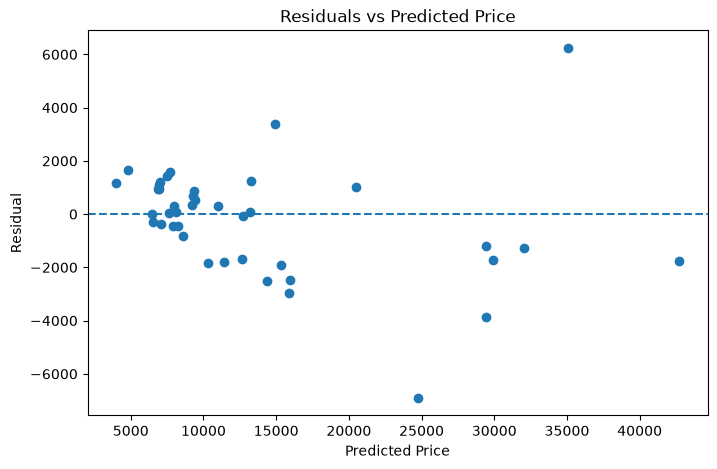

In [115]:
residuals = y_test_actual - y_test_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred, residuals)
plt.axhline(y=0, linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Price")
plt.show()

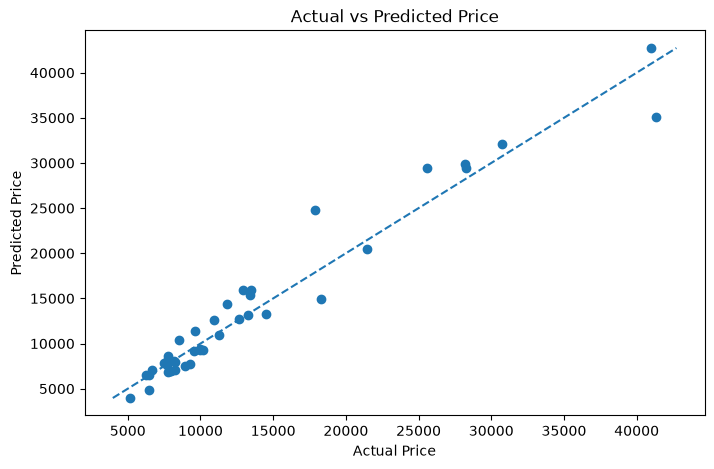

In [116]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_actual, y_test_pred)

# Perfect prediction line
min_value = min(y_test_actual.min(), y_test_pred.min())
max_value = max(y_test_actual.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

plt.show()

In [117]:
results = pd.DataFrame({
    'Actual': y_test_actual,
    'Predicted': y_test_pred,
    'Residual': residuals
})

results['Absolute_Error'] = abs(results['Residual'])

results['Percentage_Error'] = (
    results['Absolute_Error'] / results['Actual']
) * 100

results.sort_values(
    'Absolute_Error',
    ascending=False
).head(10)

,Actual,Predicted,Residual,Absolute_Error,Percentage_Error
9,17859.167,24765.927485,-6906.760485,6906.760485,38.673475
16,41315.000,35073.841609,6241.158391,6241.158391,15.106277
67,25552.000,29402.328218,-3850.328218,3850.328218,15.068598
65,18280.000,14901.105305,3378.894695,3378.894695,18.484107
194,12940.000,15908.702072,-2968.702072,2968.702072,22.942056
132,11850.000,14370.699208,-2520.699208,2520.699208,21.271723
101,13499.000,15979.999398,-2480.999398,2480.999398,18.379135
195,13415.000,15334.179045,-1919.179045,1919.179045,14.306217
60,8495.000,10342.997398,-1847.997398,1847.997398,21.753942
168,9639.000,11439.724303,-1800.724303,1800.724303,18.681651


In [118]:
results.sort_values(
    'Percentage_Error',
    ascending=False
).head(10)

,Actual,Predicted,Residual,Absolute_Error,Percentage_Error
9,17859.167,24765.927485,-6906.760485,6906.760485,38.673475
30,6479.000,4808.313078,1670.686922,1670.686922,25.786185
194,12940.000,15908.702072,-2968.702072,2968.702072,22.942056
18,5151.000,3969.492137,1181.507863,1181.507863,22.937446
60,8495.000,10342.997398,-1847.997398,1847.997398,21.753942
132,11850.000,14370.699208,-2520.699208,2520.699208,21.271723
168,9639.000,11439.724303,-1800.724303,1800.724303,18.681651
65,18280.000,14901.105305,3378.894695,3378.894695,18.484107
101,13499.000,15979.999398,-2480.999398,2480.999398,18.379135
162,9258.000,7688.024756,1569.975244,1569.975244,16.958039


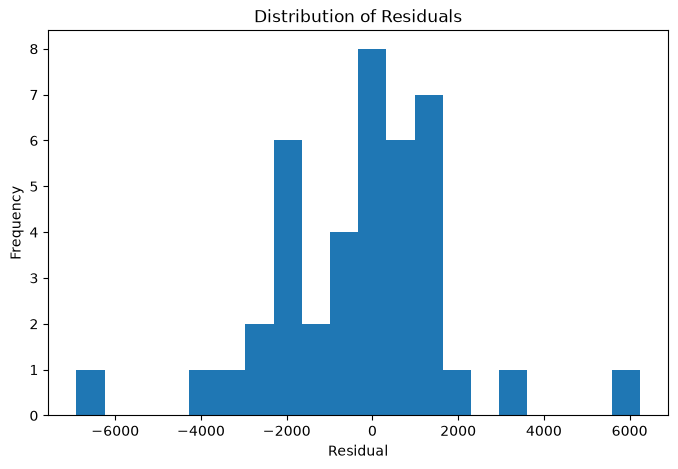

In [119]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=20)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

In [120]:
final_features = model_final.named_steps['preprocessor'].get_feature_names_out()

print(final_features)
print("Number of features:", len(final_features))

['num__wheelbase' 'num__carlength' 'num__carwidth' 'num__carheight'
 'num__curbweight' 'num__enginesize' 'num__boreratio' 'num__stroke'
 'num__compressionratio' 'num__horsepower' 'num__peakrpm' 'num__citympg'
 'num__highwaympg' 'cat__symboling_-1' 'cat__symboling_0'
 'cat__symboling_1' 'cat__symboling_2' 'cat__symboling_3'
 'cat__fueltype_gas' 'cat__aspiration_turbo' 'cat__doornumber_two'
 'cat__carbody_hardtop' 'cat__carbody_hatchback' 'cat__carbody_sedan'
 'cat__carbody_wagon' 'cat__drivewheel_fwd' 'cat__drivewheel_rwd'
 'cat__CarCompany_audi' 'cat__CarCompany_bmw' 'cat__CarCompany_buick'
 'cat__CarCompany_chevrolet' 'cat__CarCompany_dodge'
 'cat__CarCompany_honda' 'cat__CarCompany_isuzu' 'cat__CarCompany_jaguar'
 'cat__CarCompany_mazda' 'cat__CarCompany_mercury'
 'cat__CarCompany_mitsubishi' 'cat__CarCompany_nissan'
 'cat__CarCompany_peugeot' 'cat__CarCompany_plymouth'
 'cat__CarCompany_porsche' 'cat__CarCompany_renault'
 'cat__CarCompany_saab' 'cat__CarCompany_subaru' 'cat__CarComp

In [121]:
# print(len(final_features))
# print(len(model_final.named_steps['regressor'].coef_))

In [122]:
coefficients = pd.DataFrame({
    'Feature': final_features,
    'Coefficient': model_final.named_steps['regressor'].coef_
})

coefficients

,Feature,Coefficient
0,num__wheelbase,0.097954
1,num__carlength,-0.025307
2,num__carwidth,-0.003100
3,num__carheight,-0.066332
4,num__curbweight,0.239520
5,num__enginesize,0.092649
6,num__boreratio,-0.030110
7,num__stroke,0.011442
8,num__compressionratio,0.033128
9,num__horsepower,0.002730


In [123]:
coefficients['Absolute_Coefficient'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

coefficients

,Feature,Coefficient,Absolute_Coefficient
41,cat__CarCompany_porsche,0.439429,0.439429
28,cat__CarCompany_bmw,0.394038,0.394038
37,cat__CarCompany_mitsubishi,-0.311622,0.311622
40,cat__CarCompany_plymouth,-0.277235,0.277235
24,cat__carbody_wagon,-0.271869,0.271869
22,cat__carbody_hatchback,-0.270037,0.270037
31,cat__CarCompany_dodge,-0.258394,0.258394
4,num__curbweight,0.239520,0.239520
23,cat__carbody_sedan,-0.222559,0.222559
27,cat__CarCompany_audi,0.206467,0.206467


#### Interpretation of Coefficients

The coefficients were examined to understand the direction and relative influence of the predictors on car price. The model was trained using the log-transformed target variable, so the coefficients represent their relationship with log-transformed car price.

The absolute value of the coefficients was used to identify the predictors with relatively larger effects. Positive coefficients indicate a positive relationship with predicted car price, while negative coefficients indicate a negative relationship, holding other variables constant.

For categorical variables, the coefficients represent the effect relative to their respective reference categories.

In [124]:
coefficients.head(10)

,Feature,Coefficient,Absolute_Coefficient
41,cat__CarCompany_porsche,0.439429,0.439429
28,cat__CarCompany_bmw,0.394038,0.394038
37,cat__CarCompany_mitsubishi,-0.311622,0.311622
40,cat__CarCompany_plymouth,-0.277235,0.277235
24,cat__carbody_wagon,-0.271869,0.271869
22,cat__carbody_hatchback,-0.270037,0.270037
31,cat__CarCompany_dodge,-0.258394,0.258394
4,num__curbweight,0.239520,0.239520
23,cat__carbody_sedan,-0.222559,0.222559
27,cat__CarCompany_audi,0.206467,0.206467


### Key Observations

- **CarCompany_porsche** and **CarCompany_bmw** have the largest positive coefficient magnitudes, indicating a relatively strong positive association with predicted car price compared with the reference company.

- **CarCompany_mitsubishi** and **CarCompany_plymouth** have relatively large negative coefficient magnitudes, indicating a negative association with predicted car price compared with their reference category.

- **Carbody_wagon** and **carbody_hatchback** also have relatively large negative coefficient magnitudes compared with the reference carbody category.

- **Curbweight** has one of the largest coefficient magnitudes among the numerical variables, indicating that it is an important predictor in the model.

- The coefficient signs indicate the **direction** of the relationship. The coefficient magnitudes provide an indication of the relative strength of association between the predictors and the log-transformed car price.

## Conclusion

The final Multiple Linear Regression model achieved a Test R² of 0.95, indicating that the model explains approximately 95% of the variation in car prices on the test dataset.

The model identified several variables that have relatively strong associations with car prices. The final model also showed good generalisation, with a training R² of 0.96 and a test R² of 0.95.

Overall, the model provides useful insights into the factors influencing car prices and can help Geely Auto understand pricing dynamics in the US market and support pricing and business strategy decisions.